In [ ]:
from pathlib import Path
import torch

PROJECT_DIR = Path("/content/cxr_anomaly_project")

folders = [
    "configs",
    "splits",
    "weights",
    "features/imagenet",
    "features/chess",
    "memory_banks/imagenet",
    "memory_banks/chess",
    "results",
    "heatmaps",
]

for folder in folders:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project Directory:", PROJECT_DIR)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("The GPU is not connected. To process images, enable the GPU in the environment settings.")

Папка проекта: /content/cxr_anomaly_project
Устройство: cpu
GPU не подключён. Для обработки снимков включи GPU в настройках среды.


In [ ]:
import shutil
from google.colab import files

backup_dir = Path("/content/cxr_backup")
backup_dir.mkdir(exist_ok=True)

for folder in ["configs", "splits", "results"]:
    source = PROJECT_DIR / folder
    target = backup_dir / folder

    if target.exists():
        shutil.rmtree(target)

    shutil.copytree(source, target)

archive_path = shutil.make_archive(
    "/content/cxr_results_backup",
    "zip",
    root_dir=backup_dir,
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import zipfile
from pathlib import Path
from urllib.parse import quote

import pandas as pd
import requests

PROJECT_DIR = Path("/content/cxr_anomaly_project")
DATA_DIR = PROJECT_DIR / "data" / "chexpert_normal_ap_100"
IMAGE_DIR = DATA_DIR / "images"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://www.kaggle.com/api/v1/datasets/download/"
    "ashery/chexpert/"
)

def download_file(file_path):
    url = BASE_URL + quote(file_path, safe="")

    response = requests.get(url, timeout=(30, 180))
    response.raise_for_status()

    if "text/html" in response.headers.get("Content-Type", ""):
        raise RuntimeError(
        )

    data = response.content
    buffer = io.BytesIO(data)

    if zipfile.is_zipfile(buffer):
        with zipfile.ZipFile(buffer) as archive:
            candidates = [
                name for name in archive.namelist()
                if not name.endswith("/")
                and Path(name).name == Path(file_path).name
            ]

            if len(candidates) != 1:
                raise RuntimeError("Didn't file in ZIP.")

            return archive.read(candidates[0])

    return data


csv_path = DATA_DIR / "train.csv"

if not csv_path.exists():
    csv_bytes = download_file("train.csv")

    pd.read_csv(io.BytesIO(csv_bytes), nrows=5)
    csv_path.write_bytes(csv_bytes)

df = pd.read_csv(csv_path)

print("Rows:", len(df))
display(df.head(3))

Rows: 223414


,Path,Sex,Age,Frontal/Lateral,AP/PA,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices
0,CheXpert-v1.0-small/train/patient00001/study1/...,Female,68,Frontal,AP,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0
1,CheXpert-v1.0-small/train/patient00002/study2/...,Female,87,Frontal,AP,NaN,NaN,-1.0,1.0,NaN,-1.0,-1.0,NaN,-1.0,NaN,-1.0,NaN,1.0,NaN
2,CheXpert-v1.0-small/train/patient00002/study1/...,Female,83,Frontal,AP,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN


In [ ]:
disease_columns = [
    "Enlarged Cardiomediastinum",
    "Cardiomegaly",
    "Lung Opacity",
    "Lung Lesion",
    "Edema",
    "Consolidation",
    "Pneumonia",
    "Atelectasis",
    "Pneumothorax",
    "Pleural Effusion",
    "Pleural Other",
    "Fracture",
]

is_frontal = (
    df["Frontal/Lateral"].eq("Frontal")
    & df["AP/PA"].eq("AP")
)

is_normal = df["No Finding"].eq(1)

# We exclude positive (1) and indeterminate (-1) test results
has_disease_or_uncertainty = (
    df[disease_columns].isin([1, -1]).any(axis=1)
)

# For the first bank, we also exclude undefined devices
has_devices = df["Support Devices"].isin([1, -1])

eligible = df.loc[
    is_frontal
    & is_normal
    & ~has_disease_or_uncertainty
    & ~has_devices
].copy()

eligible["patient_id"] = eligible["Path"].str.extract(
    r"(patient\d+)", expand=False
)

if eligible["patient_id"].isna().any():
    raise ValueError("We were unable to identify the patient for some of the images.")

# We randomly select one suitable photo for each patient
one_per_patient = (
    eligible.sample(frac=1, random_state=42)
    .drop_duplicates("patient_id")
)

if len(one_per_patient) < 100:
    raise ValueError(
        f"Only eligible patients {len(one_per_patient)}."
    )

selected = one_per_patient.sample(
    n=100, random_state=42
).reset_index(drop=True)

# On Kaggle, paths start with “train/”, without “CheXpert-v1.0-small/”
selected["kaggle_path"] = selected["Path"].str.replace(
    r"^.*?train/", "train/", regex=True
)

selected["local_filename"] = selected["kaggle_path"].str.replace(
    "/", "__", regex=False
)

selected.to_csv(DATA_DIR / "selected_100.csv", index=False)

print("Number of photos selected:", len(selected))
print("Various patients:", selected["patient_id"].nunique())
print("\nProjections:")
print(selected["AP/PA"].value_counts())

display(selected[["patient_id", "AP/PA", "Path"]].head())

Выбрано снимков: 100
Разных пациентов: 100

Проекции:
AP/PA
AP    100
Name: count, dtype: int64


,patient_id,AP/PA,Path
0,patient04881,AP,CheXpert-v1.0-small/train/patient04881/study3/...
1,patient57794,AP,CheXpert-v1.0-small/train/patient57794/study1/...
2,patient13888,AP,CheXpert-v1.0-small/train/patient13888/study1/...
3,patient10368,AP,CheXpert-v1.0-small/train/patient10368/study8/...
4,patient07424,AP,CheXpert-v1.0-small/train/patient07424/study2/...


In [ ]:
from PIL import Image
from tqdm.auto import tqdm

def image_is_valid(path):
    try:
        with Image.open(path) as image:
            image.verify()
        return True
    except Exception:
        return False


for row in tqdm(
    selected.itertuples(index=False),
    total=len(selected),
    desc="Uploading photos",
):
    destination = IMAGE_DIR / row.local_filename

    if destination.exists() and image_is_valid(destination):
        continue

    image_bytes = download_file(row.kaggle_path)

    # We check to make sure we've received an image and not an error page
    with Image.open(io.BytesIO(image_bytes)) as image:
        image.verify()

    temporary = destination.with_suffix(".part")
    temporary.write_bytes(image_bytes)
    temporary.replace(destination)

valid_count = sum(
    image_is_valid(IMAGE_DIR / name)
    for name in selected["local_filename"]
)

print(f"Done: {valid_count}/100 images")
print("Directory:", IMAGE_DIR)

Загрузка снимков:   0%|          | 0/100 [00:00<?, ?it/s]

Готово: 100/100 изображений
Папка: /content/cxr_anomaly_project/data/chexpert_normal_ap_100/images


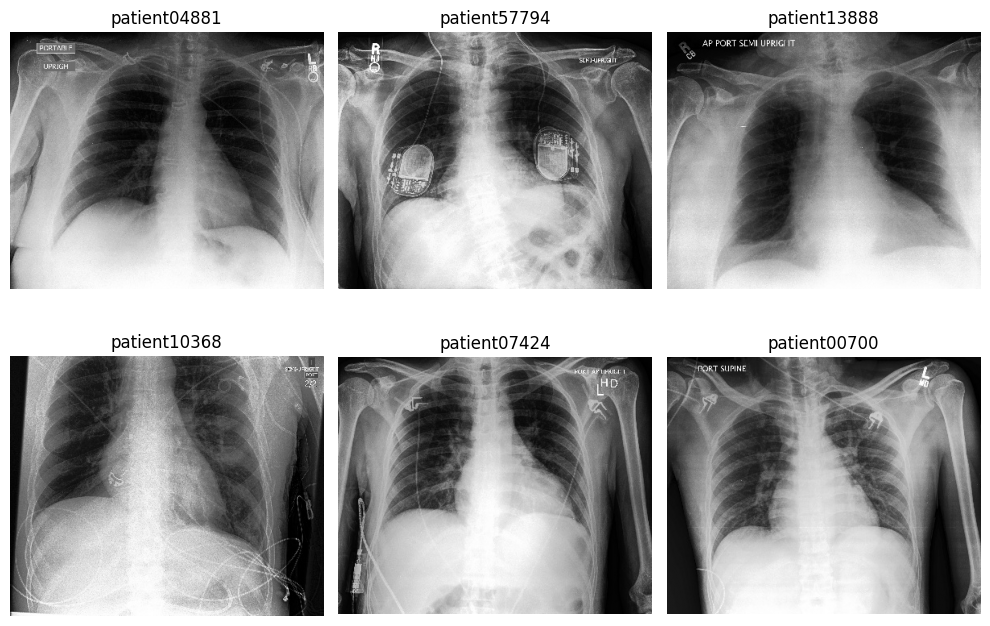

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for ax, row in zip(axes.flat, selected.head(6).itertuples(index=False)):
    with Image.open(IMAGE_DIR / row.local_filename) as image:
        ax.imshow(image.convert("L"), cmap="gray")

    ax.set_title(f"{row.patient_id}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
%pip install -q torchxrayvision

import numpy as np
import torch
import torchxrayvision as xrv
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage
from matplotlib.colors import ListedColormap

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

seg_model = xrv.baseline_models.chestx_det.PSPNet()
seg_model = seg_model.to(DEVICE).eval()

# Find the desired outputs of the model by name
LEFT_LUNG_INDEX = seg_model.targets.index("Left Lung")
RIGHT_LUNG_INDEX = seg_model.targets.index("Right Lung")

print("Device:", DEVICE)
print("Model is ready")

Устройство: cpu
Модель готова


In [ ]:
IMAGE_SIZE = 512

def prepare_image(image_path):
    with Image.open(image_path) as source:
        image = source.convert("L")

    width, height = image.size
    scale = IMAGE_SIZE / max(width, height)

    new_width = max(1, round(width * scale))
    new_height = max(1, round(height * scale))

    resized = image.resize(
        (new_width, new_height),
        Image.Resampling.BILINEAR,
    )

    canvas = Image.new("L", (IMAGE_SIZE, IMAGE_SIZE), color=0)

    offset_x = (IMAGE_SIZE - new_width) // 2
    offset_y = (IMAGE_SIZE - new_height) // 2

    canvas.paste(resized, (offset_x, offset_y))

    image_array = np.array(canvas, dtype=np.float32)

    # The area of this image, excluding the added margins
    valid_area = np.zeros(
        (IMAGE_SIZE, IMAGE_SIZE), dtype=bool
    )
    valid_area[
        offset_y:offset_y + new_height,
        offset_x:offset_x + new_width,
    ] = True

    return image_array, valid_area

In [ ]:
def largest_component(mask):
    """Returns the largest contiguous region of the mask."""
    labels, count = ndimage.label(mask)

    if count == 0:
        return np.zeros_like(mask, dtype=bool)

    sizes = np.bincount(labels.ravel())
    sizes[0] = 0

    return labels == sizes.argmax()


def divide_lung(mask, first_id):
    """It divides the lung mask into three zones vertically."""
    regions = np.zeros(mask.shape, dtype=np.uint8)

    rows = np.where(mask)[0]

    if len(rows) == 0:
        raise ValueError("The model did not highlight one of the lungs.")

    top = rows.min()
    bottom = rows.max()
    height = bottom - top + 1

    y, x = np.where(mask)

    # Upper zone: 0, middle zone: 1, lower zone: 2
    zone = np.minimum(
        ((y - top) * 3) // height,
        2,
    )

    regions[y, x] = first_id + zone

    return regions


@torch.inference_mode()
def get_lung_regions(image_path):
    image_array, valid_area = prepare_image(image_path)

    # PSPNet expects an input in the range [-1024, 1024]
    normalized = (image_array / 255.0) * 2048.0 - 1024.0

    tensor = torch.from_numpy(normalized)
    tensor = tensor.unsqueeze(0).unsqueeze(0).to(DEVICE)

    logits = seg_model(tensor)
    probabilities = torch.sigmoid(logits)[0].cpu().numpy()

    left_probability = probabilities[LEFT_LUNG_INDEX]
    right_probability = probabilities[RIGHT_LUNG_INDEX]

    left_mask = (left_probability > 0.5) & valid_area
    right_mask = (right_probability > 0.5) & valid_area

    # If the masks overlap, choose the more confident answer
    overlap = left_mask & right_mask

    left_mask[overlap] = (
        left_probability[overlap] >= right_probability[overlap]
    )
    right_mask[overlap] = (
        right_probability[overlap] > left_probability[overlap]
    )

    left_mask = largest_component(left_mask)
    right_mask = largest_component(right_mask)

    right_regions = divide_lung(right_mask, first_id=1)
    left_regions = divide_lung(left_mask, first_id=4)

    regions = right_regions + left_regions

    return image_array, regions

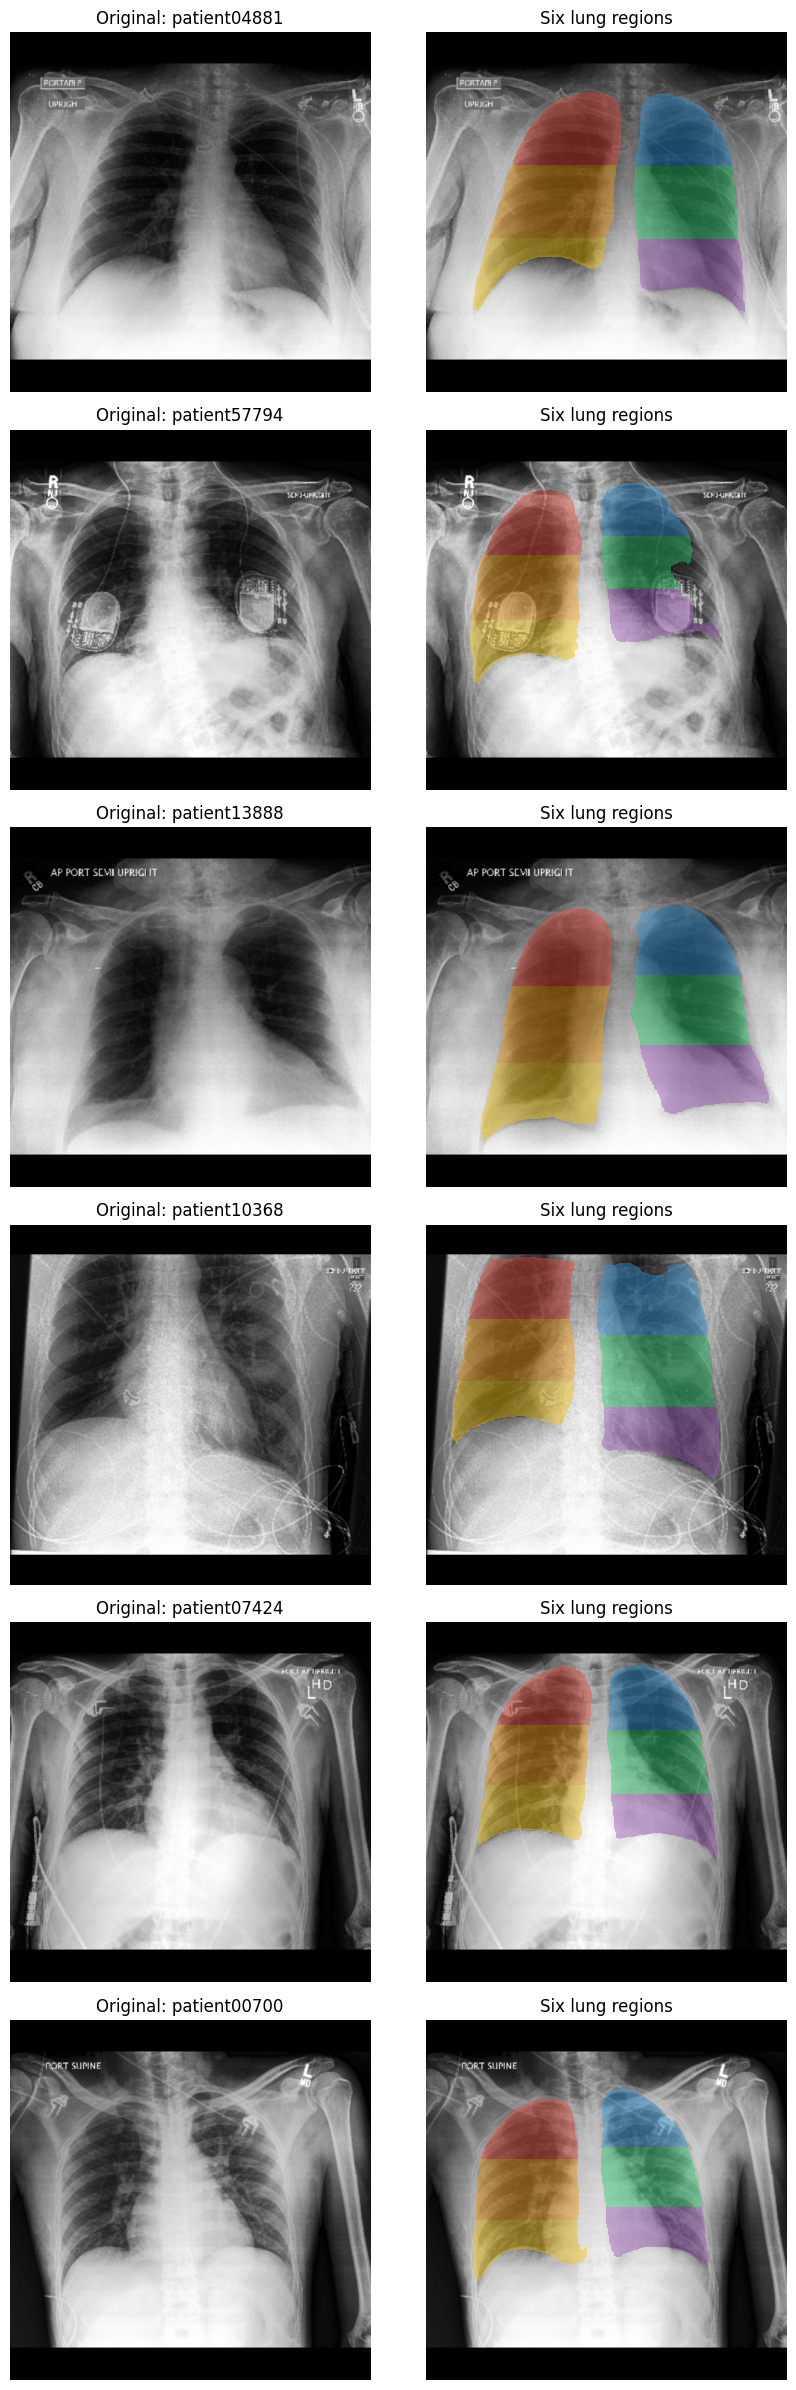

In [ ]:
region_colors = ListedColormap([
    "black",       # 0: background
    "#e74c3c",     # 1: upper right
    "#f39c12",     # 2: right middle
    "#f1c40f",     # 3: bottom right
    "#3498db",     # 4: upper left
    "#2ecc71",     # 5: left middle
    "#9b59b6",     # 6: lower left
])

examples = selected.head(6)

fig, axes = plt.subplots(
    len(examples), 2,
    figsize=(9, 4 * len(examples)),
)

for i, row in enumerate(examples.itertuples(index=False)):
    image_path = IMAGE_DIR / row.local_filename

    image_array, regions = get_lung_regions(image_path)

    axes[i, 0].imshow(image_array, cmap="gray")
    axes[i, 0].set_title(f"Original: {row.patient_id}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(image_array, cmap="gray")

    # Do not paint over the background
    overlay = np.ma.masked_where(regions == 0, regions)

    axes[i, 1].imshow(
        overlay,
        cmap=region_colors,
        vmin=-0.5,
        vmax=6.5,
        alpha=0.45,
        interpolation="nearest",
    )

    axes[i, 1].set_title("Six lung regions")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def expanded_lung_box(mask, valid_area):
    """A rectangle around the lung with slight indentations."""
    y, x = np.where(mask)

    if len(y) == 0:
        raise ValueError("The lung is empty.")

    height = y.max() - y.min() + 1
    width = x.max() - x.min() + 1

    side_margin = max(1, round(width * 0.05))
    top_margin = max(1, round(height * 0.05))
    bottom_margin = max(1, round(height * 0.15))

    # Image borders without black margins
    valid_y, valid_x = np.where(valid_area)

    x0 = max(valid_x.min(), x.min() - side_margin)
    x1 = min(valid_x.max() + 1, x.max() + 1 + side_margin)

    y0 = max(valid_y.min(), y.min() - top_margin)
    y1 = min(valid_y.max() + 1, y.max() + 1 + bottom_margin)

    return [int(x0), int(y0), int(x1), int(y1)]


def get_box_regions(image_path):
    image_array, original_regions = get_lung_regions(image_path)
    _, valid_area = prepare_image(image_path)

    right_mask = np.isin(original_regions, [1, 2, 3])
    left_mask = np.isin(original_regions, [4, 5, 6])

    right_box = expanded_lung_box(right_mask, valid_area)
    left_box = expanded_lung_box(left_mask, valid_area)

    # We determine the location of the lungs in the image
    right_center = np.where(right_mask)[1].mean()
    left_center = np.where(left_mask)[1].mean()

    # If the rectangles overlap, divide them in the middle
    overlap_start = max(right_box[0], left_box[0])
    overlap_end = min(right_box[2], left_box[2])

    if overlap_start < overlap_end:
        boundary = (overlap_start + overlap_end) // 2

        if right_center < left_center:
            right_box[2] = boundary
            left_box[0] = boundary
        else:
            left_box[2] = boundary
            right_box[0] = boundary

    regions = np.zeros_like(original_regions)

    for box, first_id in [(right_box, 1), (left_box, 4)]:
        x0, y0, x1, y1 = box

        if x1 <= x0 or y1 - y0 < 3:
            raise ValueError("The lung area turned out to be too small.")

        boundaries = np.linspace(y0, y1, 4, dtype=int)

        for zone in range(3):
            regions[
                boundaries[zone]:boundaries[zone + 1],
                x0:x1,
            ] = first_id + zone

    regions[~valid_area] = 0

    return image_array, original_regions, regions

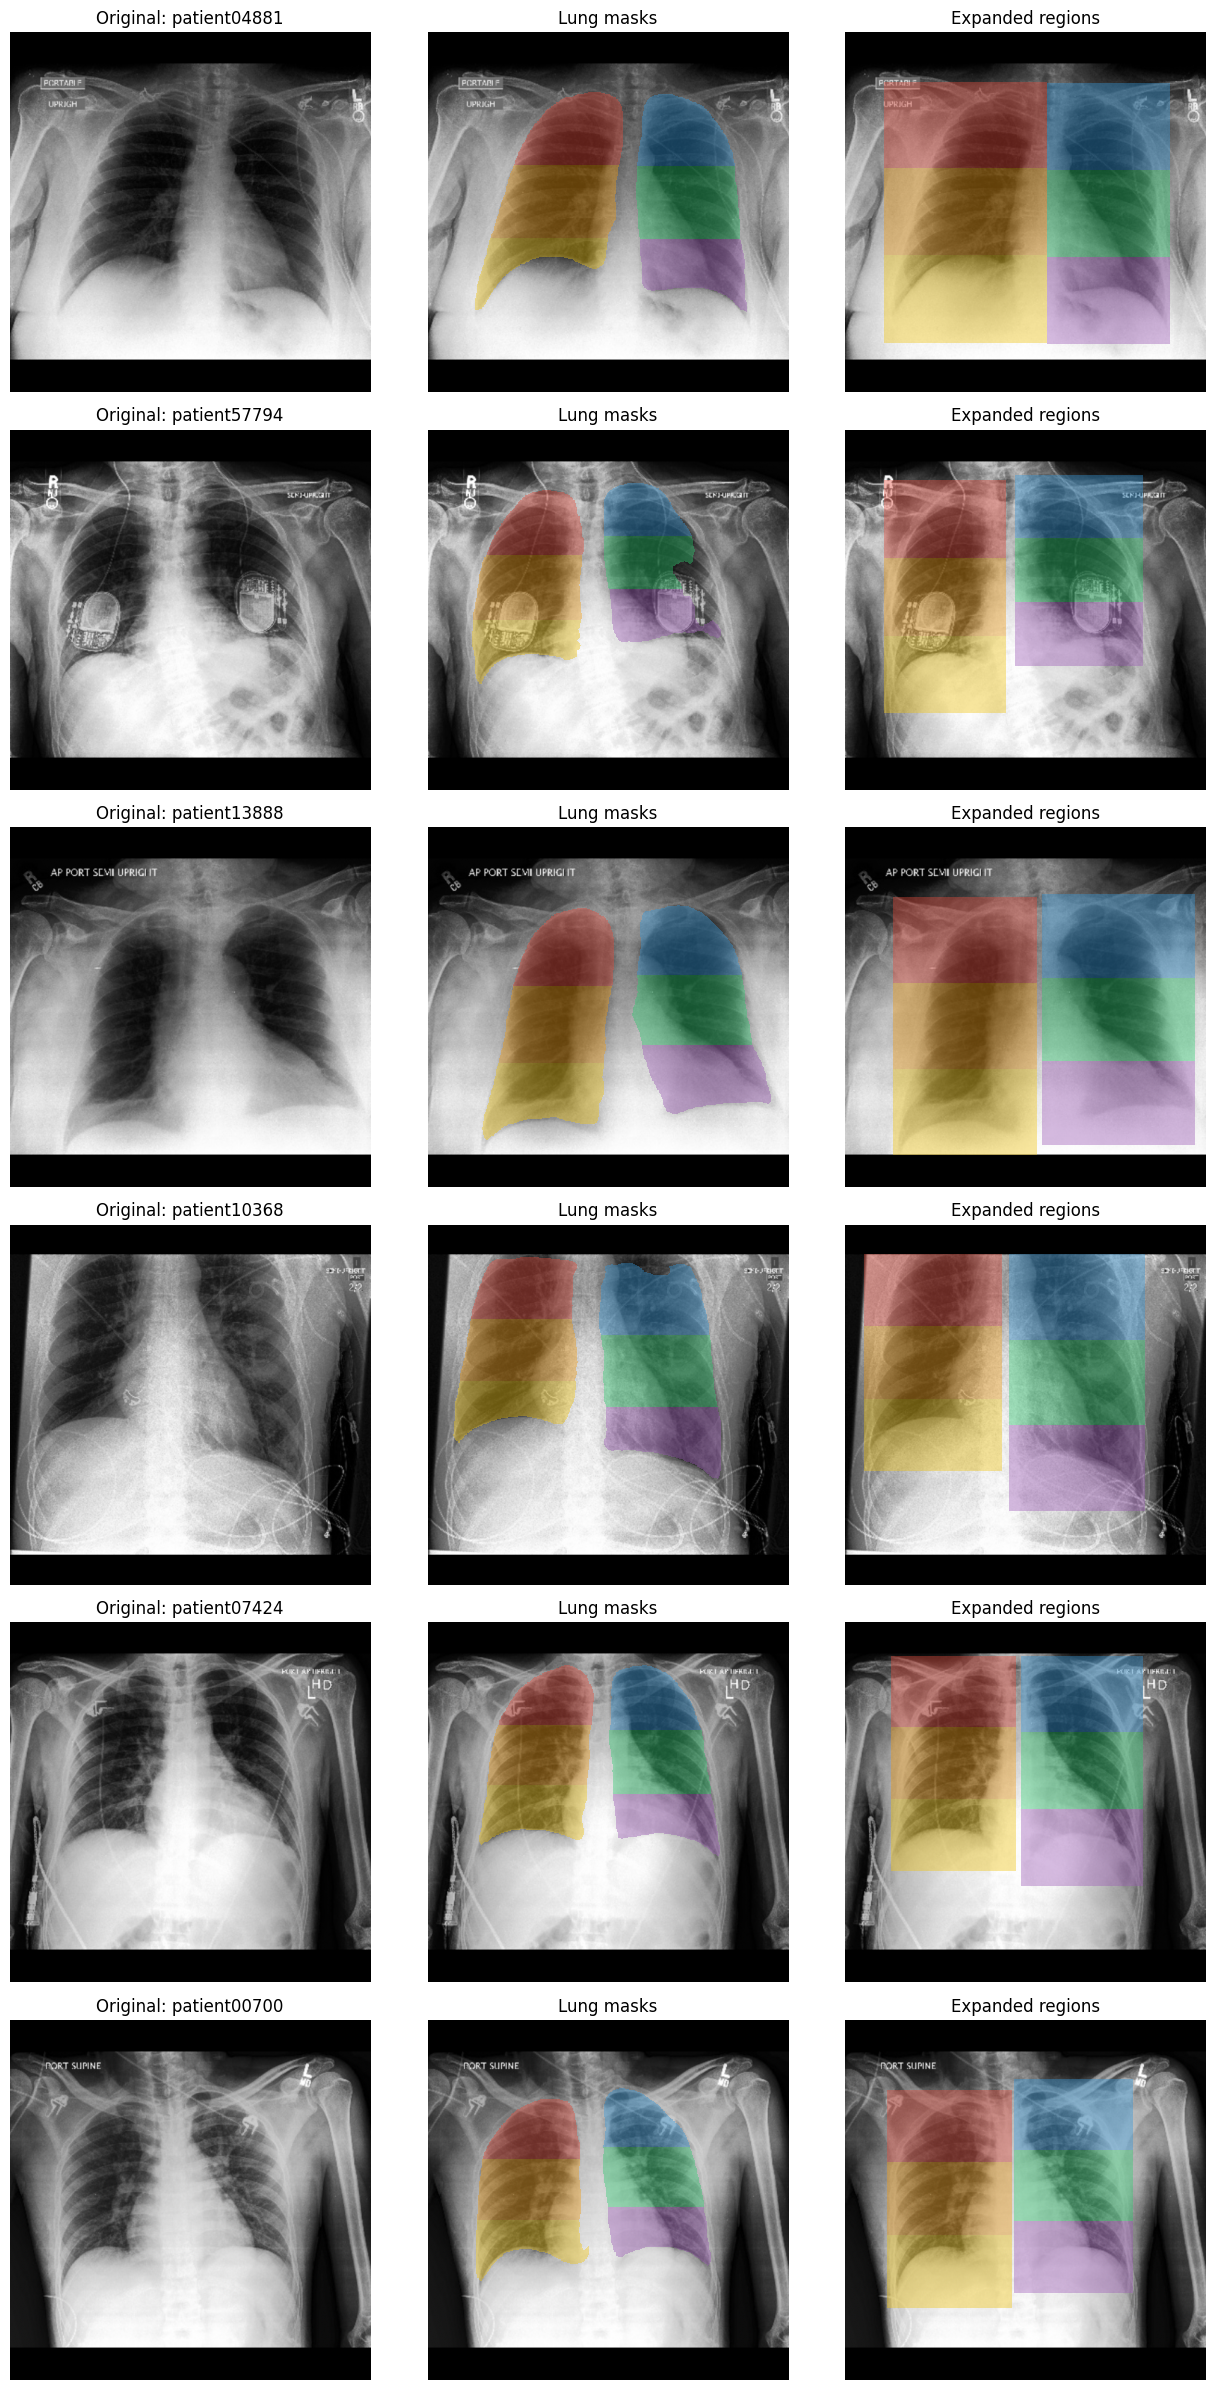

In [ ]:
examples = selected.head(6)

fig, axes = plt.subplots(
    len(examples),
    3,
    figsize=(13, 4 * len(examples)),
    squeeze=False,
)

for i, row in enumerate(examples.itertuples(index=False)):
    image_path = IMAGE_DIR / row.local_filename

    image_array, old_regions, new_regions = get_box_regions(image_path)

    titles = [
        f"Original: {row.patient_id}",
        "Lung masks",
        "Expanded regions",
    ]

    for j in range(3):
        axes[i, j].imshow(image_array, cmap="gray")
        axes[i, j].set_title(titles[j])
        axes[i, j].axis("off")

    for column, regions in [(1, old_regions), (2, new_regions)]:
        overlay = np.ma.masked_where(regions == 0, regions)

        axes[i, column].imshow(
            overlay,
            cmap=region_colors,
            vmin=-0.5,
            vmax=6.5,
            alpha=0.4,
            interpolation="nearest",
        )

plt.tight_layout()
plt.show()

In [ ]:
import torch
import torch.nn.functional as F

from torchvision.models import resnet50, ResNet50_Weights
from torchvision.models.feature_extraction import create_feature_extractor

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

encoder = create_feature_extractor(
    model,
    return_nodes={
        "layer2": "features_2",
        "layer3": "features_3",
    },
).to(DEVICE).eval()

for parameter in encoder.parameters():
    parameter.requires_grad = False

del model

mean = torch.tensor(
    [0.485, 0.456, 0.406], device=DEVICE
).view(1, 3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225], device=DEVICE
).view(1, 3, 1, 1)

print("The encoder is ready:", DEVICE)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 75.5MB/s]


Кодировщик готов: cpu


In [ ]:
@torch.inference_mode()
def extract_patch_features(image_path):
    image_array, regions = get_lung_regions(image_path)

    # Image: [1, 3, 512, 512]
    image_tensor = torch.from_numpy(
        image_array.astype("float32") / 255.0
    )

    image_tensor = (
        image_tensor.unsqueeze(0)
        .unsqueeze(0)
        .repeat(1, 3, 1, 1)
        .to(DEVICE)
    )

    image_tensor = (image_tensor - mean) / std

    outputs = encoder(image_tensor)

    # Gathering information from neighboring positions
    features_2 = F.avg_pool2d(
        outputs["features_2"],
        kernel_size=3,
        stride=1,
        padding=1,
    )

    features_3 = F.avg_pool2d(
        outputs["features_3"],
        kernel_size=3,
        stride=1,
        padding=1,
    )

    # We resize the maps to the same size
    features_3 = F.interpolate(
        features_3,
        size=features_2.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

    feature_map = torch.cat(
        [features_2, features_3], dim=1
    )

    height, width = feature_map.shape[-2:]

    # In layer2, the step size between positions is 8 pixels.
    # We retrieve the region label at the corresponding position in the image.
    region_tensor = torch.from_numpy(regions.astype("int64"))
    patch_regions = region_tensor[::8, ::8]

    if patch_regions.shape != (height, width):
        raise ValueError("Размеры карты признаков и регионов не совпадают.")

    # [number of items, 1536]
    vectors = (
        feature_map[0]
        .permute(1, 2, 0)
        .reshape(-1, feature_map.shape[1])
        .cpu()
    )

    region_ids = patch_regions.reshape(-1)

    # We rule out lesions outside the lungs
    inside_lungs = region_ids > 0

    return vectors[inside_lungs], region_ids[inside_lungs]

In [ ]:
first_path = IMAGE_DIR / selected.iloc[0]["local_filename"]

vectors, region_ids = extract_patch_features(first_path)

print("Form of traits:", vectors.shape)

for region in range(1, 7):
    count = (region_ids == region).sum().item()
    print(f"Region {region}: {count} vectors")

Форма признаков: torch.Size([1150, 1536])
Регион 1: 193 векторов
Регион 2: 260 векторов
Регион 3: 123 векторов
Регион 4: 163 векторов
Регион 5: 232 векторов
Регион 6: 179 векторов


In [ ]:
from tqdm.auto import tqdm

BANK_DIR = PROJECT_DIR / "memory_banks" / "imagenet"
BANK_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = BANK_DIR / "regional_ap_masks_v1.pt"

MAX_VECTORS = 2000
FEATURE_DIM = 1536

region_names = {
    1: "right_upper",
    2: "right_middle",
    3: "right_lower",
    4: "left_upper",
    5: "left_middle",
    6: "left_lower",
}

config = {
    "encoder": "resnet50_imagenet_v2",
    "regions": "lung_masks_v1",
    "image_size": IMAGE_SIZE,
    "max_vectors": MAX_VECTORS,
    "filenames": selected["local_filename"].tolist(),
}

generator = torch.Generator().manual_seed(42)

if CHECKPOINT_PATH.exists():
    state = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True,
    )

    if state["config"] != config:
        raise ValueError(
            "The settings or selection have changed."
            "For the new experiment, specify a different CHECKPOINT_PATH name."
        )

    banks = state["banks"]
    priorities = state["priorities"]
    completed = set(state["completed"])
    generator.set_state(state["random_state"])

    print("Let's continue. Already processed:", len(completed))

else:
    banks = {
        region: torch.empty((0, FEATURE_DIM))
        for region in region_names
    }

    priorities = {
        region: torch.empty(0)
        for region in region_names
    }

    completed = set()


def save_checkpoint():
    state = {
        "config": config,
        "banks": banks,
        "priorities": priorities,
        "completed": sorted(completed),
        "random_state": generator.get_state(),
    }

    temporary = CHECKPOINT_PATH.with_suffix(".tmp")
    torch.save(state, temporary)
    temporary.replace(CHECKPOINT_PATH)


for row in tqdm(
    selected.itertuples(index=False),
    total=len(selected),
    desc="Building Banks",
):
    if row.local_filename in completed:
        continue

    image_path = IMAGE_DIR / row.local_filename
    vectors, region_ids = extract_patch_features(image_path)

    if not torch.isfinite(vectors).all():
        raise ValueError(f"Incorrect characteristics: {row.local_filename}")

    for region in region_names:
        new_vectors = vectors[region_ids == region]

        # Random priority allows you to keep a sample
        # from all processed patches, not just the most recent ones.
        new_priorities = torch.rand(
            len(new_vectors),
            generator=generator,
        )

        candidates = torch.cat(
            [banks[region], new_vectors], dim=0
        )

        candidate_priorities = torch.cat(
            [priorities[region], new_priorities]
        )

        keep_count = min(MAX_VECTORS, len(candidates))

        keep_indices = torch.topk(
            candidate_priorities, k=keep_count
        ).indices

        banks[region] = candidates[keep_indices]
        priorities[region] = candidate_priorities[keep_indices]

    completed.add(row.local_filename)

    if len(completed) % 10 == 0:
        save_checkpoint()

save_checkpoint()

print("\nNumber of photos processed:", len(completed))

for region, name in region_names.items():
    print(f"{name}: {tuple(banks[region].shape)}")

if any(len(bank) == 0 for bank in banks.values()):
    raise ValueError("One of the banks is empty—we need to check the masks.")

print("\nThe banks have been preserved:", CHECKPOINT_PATH)

Построение банков:   0%|          | 0/100 [00:00<?, ?it/s]


Обработано снимков: 100
right_upper: (2000, 1536)
right_middle: (2000, 1536)
right_lower: (2000, 1536)
left_upper: (2000, 1536)
left_middle: (2000, 1536)
left_lower: (2000, 1536)

Банки сохранены: /content/cxr_anomaly_project/memory_banks/imagenet/regional_ap_masks_v1.pt


In [ ]:
from google.colab import files

files.download(str(CHECKPOINT_PATH))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import io
import numpy as np
import pandas as pd
from PIL import Image

TEST_DIR = PROJECT_DIR / "data" / "demo_ap"
TEST_DIR.mkdir(parents=True, exist_ok=True)

candidates = df.copy()

candidates["patient_id"] = candidates["Path"].str.extract(
    r"(patient\d+)", expand=False
)

bank_patients = set(selected["patient_id"])

# AP only and new patients only
candidates = candidates.loc[
    candidates["Frontal/Lateral"].eq("Frontal")
    & candidates["AP/PA"].eq("AP")
    & candidates["patient_id"].notna()
    & ~candidates["patient_id"].isin(bank_patients)
].copy()

# A typical example: the same rules as for a bank
normal_mask = (
    candidates["No Finding"].eq(1)
    & ~candidates[disease_columns].isin([1, -1]).any(axis=1)
    & ~candidates["Support Devices"].isin([1, -1])
)

normal_pool = candidates.loc[normal_mask]

if normal_pool.empty:
    raise ValueError("No suitable normal example was found.")

normal_example = normal_pool.sample(n=1, random_state=42).copy()
normal_example["example_type"] = "Normal label"

# Example with a positive diagnosis
# We exclude devices so as not to complicate the initial check
abnormal_mask = (
    candidates[disease_columns].eq(1).any(axis=1)
    & ~candidates["No Finding"].eq(1)
    & ~candidates["Support Devices"].isin([1, -1])
    & ~candidates["patient_id"].isin(normal_example["patient_id"])
)

abnormal_pool = candidates.loc[abnormal_mask]

if abnormal_pool.empty:
    raise ValueError("No suitable pathological example was found.")

abnormal_example = abnormal_pool.sample(n=1, random_state=42).copy()
abnormal_example["example_type"] = "Abnormal label"

demo = pd.concat(
    [normal_example, abnormal_example],
    ignore_index=True,
)

demo["kaggle_path"] = demo["Path"].str.replace(
    r"^.*?train/", "train/", regex=True
)

demo["local_filename"] = demo["kaggle_path"].str.replace(
    "/", "__", regex=False
)

for row in demo.itertuples(index=False):
    destination = TEST_DIR / row.local_filename

    if not destination.exists() or not image_is_valid(destination):
        content = download_file(row.kaggle_path)

        with Image.open(io.BytesIO(content)) as image:
            image.verify()

        destination.write_bytes(content)

demo.to_csv(TEST_DIR / "demo_selection.csv", index=False)

display(demo[["patient_id", "AP/PA", "example_type"]])

for _, row in demo.iterrows():
    findings = [
        name for name in disease_columns
        if row[name] == 1
    ]
    print(row["example_type"], "— tags:", findings or ["No Finding"])

,patient_id,AP/PA,example_type
0,patient11800,AP,Normal label
1,patient21033,AP,Abnormal label


Normal label — метки: ['No Finding']
Abnormal label — метки: ['Consolidation']


In [ ]:
import math
import torch
import torch.nn.functional as F

K = 1
TOP_FRACTION = 0.01

# We verify that the bank is constructed across the entire selected hundred
if len(completed) != len(selected):
    raise RuntimeError(
        f"The bank isn't ready yet: processed {len(completed)}/{len(selected)}."
    )

banks_device = {
    region: bank.to(DEVICE)
    for region, bank in banks.items()
}


@torch.inference_mode()
def calculate_anomaly(image_path):
    vectors, region_ids = extract_patch_features(image_path)

    patch_scores = torch.zeros(len(vectors), dtype=torch.float32)

    for region in range(1, 7):
        positions = torch.where(region_ids == region)[0]

        if len(positions) == 0:
            continue

        reference = banks_device[region]

        if len(reference) < K:
            raise ValueError(f"There are not enough vectors in the region {region}.")

        # We compare in small batches to conserve memory
        for chunk_positions in positions.split(256):
            query = vectors[chunk_positions].to(DEVICE)

            distances = torch.cdist(query, reference, p=2)

            nearest = distances.topk(
                k=K,
                largest=False,
                dim=1,
            ).values

            patch_scores[chunk_positions] = nearest.mean(dim=1).cpu()

    if len(patch_scores) == 0:
        raise ValueError("No patches were found inside the lungs.")

    top_count = max(
        1, math.ceil(len(patch_scores) * TOP_FRACTION)
    )

    image_score = patch_scores.topk(top_count).values.mean().item()

    # We retrieve the same mask for placing ratings on the image again
    image_array, regions = get_lung_regions(image_path)

    region_grid = torch.from_numpy(
        regions.astype("int64")
    )[::8, ::8]

    valid_grid = region_grid > 0

    if not torch.equal(region_grid[valid_grid], region_ids):
        raise RuntimeError("The regional boundaries changed between calls.")

    score_grid = torch.zeros(
        region_grid.shape, dtype=torch.float32
    )
    score_grid[valid_grid] = patch_scores

    # Zoom in on the map; consider the boundary of the analysis area separately
    numerator = F.interpolate(
        score_grid[None, None],
        size=image_array.shape,
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    denominator = F.interpolate(
        valid_grid.float()[None, None],
        size=image_array.shape,
        mode="bilinear",
        align_corners=False,
    )[0, 0]

    heatmap = (
        numerator / denominator.clamp_min(1e-6)
    ).numpy()

    visible_area = (regions > 0) & (denominator.numpy() > 1e-6)

    return {
        "image": image_array,
        "heatmap": heatmap,
        "visible_area": visible_area,
        "score": image_score,
    }

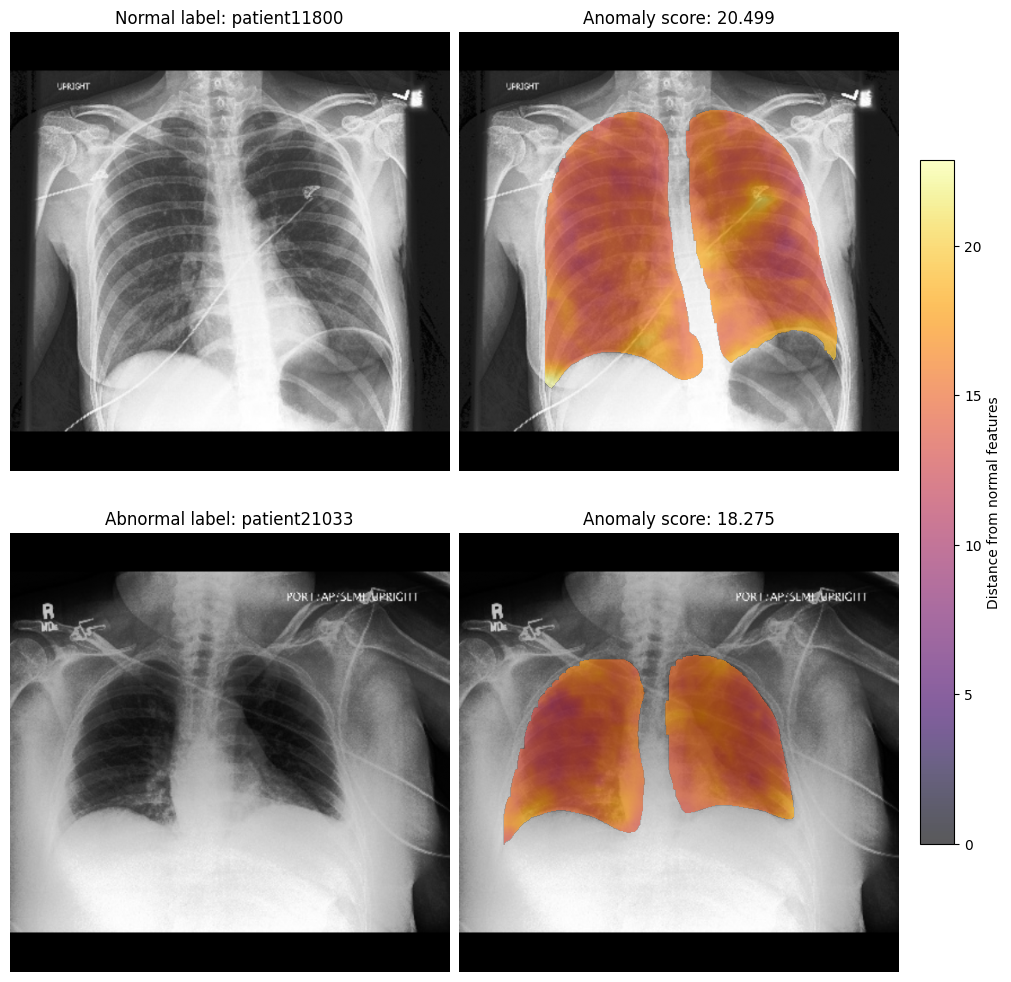

In [ ]:
import matplotlib.pyplot as plt

results = []

for row in demo.itertuples(index=False):
    result = calculate_anomaly(TEST_DIR / row.local_filename)
    result["example_type"] = row.example_type
    result["patient_id"] = row.patient_id
    results.append(result)

vmax = max(
    result["heatmap"][result["visible_area"]].max()
    for result in results
)
vmax = max(float(vmax), 1e-6)

fig, axes = plt.subplots(
    len(results), 2,
    figsize=(10, 5 * len(results)),
    squeeze=False,
    constrained_layout=True,
)

for i, result in enumerate(results):
    axes[i, 0].imshow(result["image"], cmap="gray")
    axes[i, 0].set_title(
        f'{result["example_type"]}: {result["patient_id"]}'
    )
    axes[i, 0].axis("off")

    axes[i, 1].imshow(result["image"], cmap="gray")

    visible_heatmap = np.ma.masked_where(
        ~result["visible_area"],
        result["heatmap"],
    )

    overlay = axes[i, 1].imshow(
        visible_heatmap,
        cmap="inferno",
        alpha=0.65,
        vmin=0,
        vmax=vmax,
    )

    axes[i, 1].set_title(
        f'Anomaly score: {result["score"]:.3f}'
    )
    axes[i, 1].axis("off")

fig.colorbar(
    overlay,
    ax=axes[:, 1].tolist(),
    label="Distance from normal features",
    shrink=0.7,
)

plt.show()

In [ ]:
for _, row in demo.iterrows():
    print(f"\nPatient: {row['patient_id']}")
    print("Group:", row["example_type"])

    for column in ["No Finding", *disease_columns, "Support Devices"]:
        value = row[column]

        if pd.notna(value) and value in [1, -1]:
            status = "positive" if value == 1 else "indefinite"
            print(f"  {column}: {status}")


Пациент: patient11800
Группа: Normal label
  No Finding: положительная

Пациент: patient21033
Группа: Abnormal label
  Consolidation: положительная
  Pneumonia: неопределённая
  Atelectasis: неопределённая


In [ ]:
VAL_DIR = PROJECT_DIR / "data" / "validation_ap_100"
VAL_DIR.mkdir(parents=True, exist_ok=True)

VAL_CSV = VAL_DIR / "selection.csv"

excluded_patients = (
    set(selected["patient_id"])
    | set(demo["patient_id"])
)

if VAL_CSV.exists():
    validation = pd.read_csv(VAL_CSV)

else:
    pool = df.copy()

    pool["patient_id"] = pool["Path"].str.extract(
        r"(patient\d+)", expand=False
    )

    pool = pool.loc[
        pool["Frontal/Lateral"].eq("Frontal")
        & pool["AP/PA"].eq("AP")
        & pool["patient_id"].notna()
        & ~pool["patient_id"].isin(excluded_patients)
    ].copy()

    normal_mask = (
        pool["No Finding"].eq(1)
        & ~pool[disease_columns].isin([1, -1]).any(axis=1)
        & ~pool["Support Devices"].isin([1, -1])
    )

    normal_pool = (
        pool.loc[normal_mask]
        .sample(frac=1, random_state=123)
        .drop_duplicates("patient_id")
    )

    if len(normal_pool) < 50:
        raise ValueError("There aren't enough normal patients.")

    normal = normal_pool.sample(n=50, random_state=123).copy()
    normal["label"] = 0

    abnormal_mask = (
        pool[disease_columns].eq(1).any(axis=1)
        & ~pool["No Finding"].eq(1)
        & ~pool["Support Devices"].isin([1, -1])
        & ~pool["patient_id"].isin(normal["patient_id"])
    )

    abnormal_pool = (
        pool.loc[abnormal_mask]
        .sample(frac=1, random_state=456)
        .drop_duplicates("patient_id")
    )

    if len(abnormal_pool) < 50:
        raise ValueError("There are not enough patients with the condition.")

    abnormal = abnormal_pool.sample(n=50, random_state=456).copy()
    abnormal["label"] = 1

    validation = pd.concat(
        [normal, abnormal], ignore_index=True
    )

    validation["kaggle_path"] = validation["Path"].str.replace(
        r"^.*?train/", "train/", regex=True
    )

    validation["local_filename"] = (
        validation["kaggle_path"].str.replace("/", "__", regex=False)
    )

    validation.to_csv(VAL_CSV, index=False)

assert validation["patient_id"].nunique() == 100
assert not set(validation["patient_id"]) & excluded_patients
assert validation["AP/PA"].eq("AP").all()

print("Выбрано:")
print(validation["label"].value_counts().rename(
    index={0: "Normal", 1: "С pathology"}
))

Выбрано:
label
Нормальные      50
С патологией    50
Name: count, dtype: int64


In [ ]:
import io
import json
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

SCORES_CSV = VAL_DIR / "scores_imagenet_v1.csv"
SETTINGS_JSON = VAL_DIR / "settings_imagenet_v1.json"
ERRORS_CSV = VAL_DIR / "errors_imagenet_v1.csv"

settings = {
    "bank_config": config,
    "K": K,
    "top_fraction": TOP_FRACTION,
}

if SETTINGS_JSON.exists():
    saved_settings = json.loads(SETTINGS_JSON.read_text())

    if saved_settings != settings:
        raise ValueError(
            "Настройки изменились. Для нового эксперимента "
            "используй другие имена файлов результатов."
        )
else:
    SETTINGS_JSON.write_text(
        json.dumps(settings, indent=2)
    )

if SCORES_CSV.exists():
    records = pd.read_csv(SCORES_CSV).to_dict("records")
else:
    records = []

if ERRORS_CSV.exists():
    errors = pd.read_csv(ERRORS_CSV).to_dict("records")
else:
    errors = []

finished = {record["local_filename"] for record in records}
failed = {record["local_filename"] for record in errors}

print(f"Уже обработано: {len(finished)}")
print(f"Ранее пропущено: {len(failed)}")

for row in tqdm(
    validation.itertuples(index=False),
    total=len(validation),
    desc="Проверка модели",
):
    if row.local_filename in finished or row.local_filename in failed:
        continue

    image_path = VAL_DIR / row.local_filename

    try:
        if not image_path.exists() or not image_is_valid(image_path):
            content = download_file(row.kaggle_path)

            with Image.open(io.BytesIO(content)) as image:
                image.verify()

            temporary_image = image_path.with_suffix(".part")
            temporary_image.write_bytes(content)
            temporary_image.replace(image_path)

        result = calculate_anomaly(image_path)

        records.append({
            "patient_id": row.patient_id,
            "local_filename": row.local_filename,
            "label": int(row.label),
            "score": float(result["score"]),
        })

        temporary_csv = SCORES_CSV.with_suffix(".tmp")
        pd.DataFrame(records).to_csv(temporary_csv, index=False)
        temporary_csv.replace(SCORES_CSV)

        finished.add(row.local_filename)

    except Exception as e:
        print(f"Пропущен снимок {row.local_filename}: {e}")

        errors.append({
            "patient_id": row.patient_id,
            "local_filename": row.local_filename,
            "error": str(e),
        })

        temporary_errors = ERRORS_CSV.with_suffix(".tmp")
        pd.DataFrame(errors).to_csv(temporary_errors, index=False)
        temporary_errors.replace(ERRORS_CSV)

        failed.add(row.local_filename)
        continue

scores = pd.DataFrame(records)

print("\nРезультаты проверки:")
print("Успешно обработано:", len(scores))
print("Пропущено из-за ошибок:", len(errors))
print("Всего снимков:", len(validation))

display(scores.head())

Уже обработано: 83
Ранее пропущено: 0


Проверка модели:   0%|          | 0/100 [00:00<?, ?it/s]

Пропущен снимок train__patient59666__study1__view1_frontal.jpg: Модель не выделила одно из лёгких.

Результаты проверки:
Успешно обработано: 99
Пропущено из-за ошибок: 1
Всего снимков: 100


,patient_id,local_filename,label,score
0,patient14846,train__patient14846__study3__view1_frontal.jpg,0,19.853344
1,patient07651,train__patient07651__study7__view1_frontal.jpg,0,17.991665
2,patient31087,train__patient31087__study1__view1_frontal.jpg,0,18.095106
3,patient22371,train__patient22371__study2__view1_frontal.jpg,0,18.937119
4,patient22815,train__patient22815__study4__view1_frontal.jpg,0,19.803644


Успешно обработано: 99 из 100
AUROC: 0.529
Average Precision: 0.549


,count,mean,median,min,max
label,,,,,
Normal,50,20.556492,20.547700,17.360624,25.799028
Abnormal,49,20.796234,20.747135,17.717871,26.661968


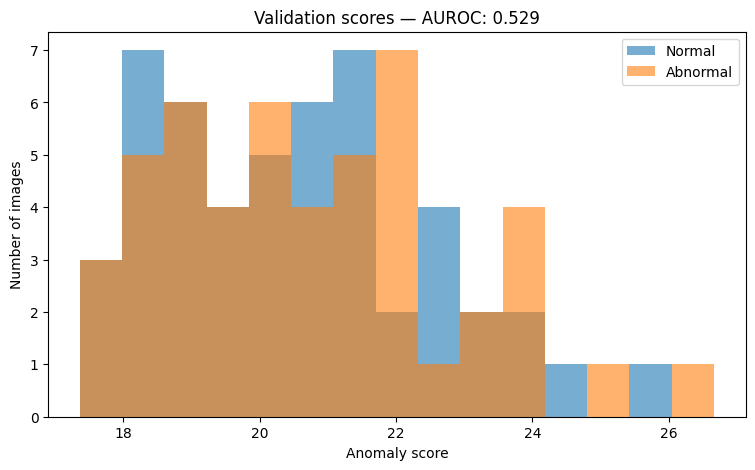

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

scores = pd.read_csv(SCORES_CSV)

print(f"Успешно обработано: {len(scores)} из 100")

if len(scores) == 0:
    raise ValueError("Нет результатов для оценки модели.")

if not np.isfinite(scores["score"]).all():
    raise ValueError("В результатах есть некорректные scores.")

if scores["label"].nunique() < 2:
    raise ValueError("Для расчёта AUROC нужны оба класса: Normal и Abnormal.")

auroc = roc_auc_score(scores["label"], scores["score"])

average_precision = average_precision_score(
    scores["label"], scores["score"]
)

print(f"AUROC: {auroc:.3f}")
print(f"Average Precision: {average_precision:.3f}")

display(
    scores.groupby("label")["score"]
    .agg(["count", "mean", "median", "min", "max"])
    .rename(index={0: "Normal", 1: "Abnormal"})
)

normal_scores = scores.loc[scores["label"] == 0, "score"]
abnormal_scores = scores.loc[scores["label"] == 1, "score"]

# Одинаковые интервалы для обеих групп
bins = np.histogram_bin_edges(scores["score"], bins=15)

plt.figure(figsize=(9, 5))

plt.hist(
    normal_scores,
    bins=bins,
    alpha=0.6,
    label="Normal",
)

plt.hist(
    abnormal_scores,
    bins=bins,
    alpha=0.6,
    label="Abnormal",
)

plt.xlabel("Anomaly score")
plt.ylabel("Number of images")
plt.title(f"Validation scores — AUROC: {auroc:.3f}")
plt.legend()
plt.show()

In [ ]:
import pandas as pd

scores = pd.read_csv(SCORES_CSV)

false_normal = (
    scores[scores["label"] == 1]
    .sort_values("score", ascending=True)
    .head(5)
)

false_abnormal = (
    scores[scores["label"] == 0]
    .sort_values("score", ascending=False)
    .head(5)
)

print("Аномальные снимки с самым низким score:")
display(false_normal)

print("Нормальные снимки с самым высоким score:")
display(false_abnormal)

Аномальные снимки с самым низким score:


,patient_id,local_filename,label,score
87,patient38538,train__patient38538__study1__view1_frontal.jpg,1,17.717871
65,patient32116,train__patient32116__study8__view1_frontal.jpg,1,17.868597
73,patient43965,train__patient43965__study1__view1_frontal.jpg,1,17.973124
79,patient37248,train__patient37248__study2__view1_frontal.jpg,1,18.000206
58,patient02748,train__patient02748__study1__view1_frontal.jpg,1,18.153456


Нормальные снимки с самым высоким score:


,patient_id,local_filename,label,score
7,patient12382,train__patient12382__study1__view1_frontal.jpg,0,25.799028
40,patient16651,train__patient16651__study1__view1_frontal.jpg,0,24.777784
29,patient07316,train__patient07316__study1__view1_frontal.jpg,0,23.825403
49,patient37792,train__patient37792__study1__view1_frontal.jpg,0,23.665594
9,patient09506,train__patient09506__study7__view1_frontal.jpg,0,23.279388


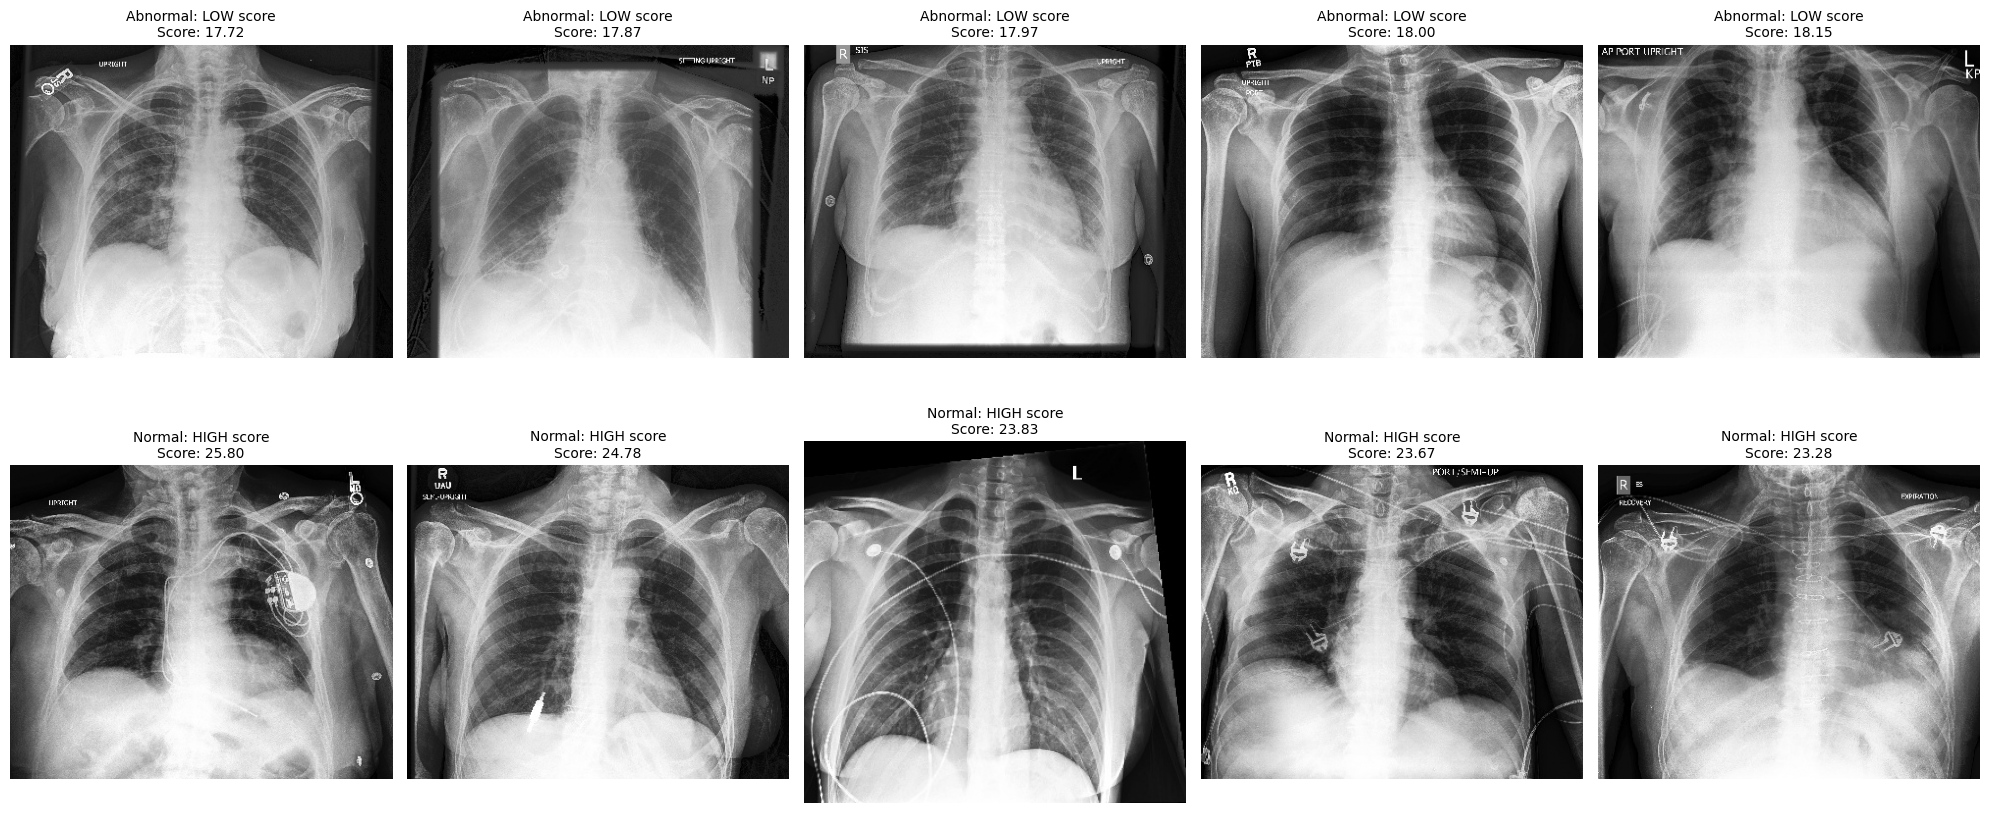

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(20, 9))

groups = [
    ("Abnormal: LOW score", false_normal),
    ("Normal: HIGH score", false_abnormal),
]

for row_idx, (title, group) in enumerate(groups):
    for col_idx, (_, item) in enumerate(group.iterrows()):
        image_path = VAL_DIR / item["local_filename"]

        ax = axes[row_idx, col_idx]

        with Image.open(image_path) as img:
            ax.imshow(img.convert("L"), cmap="gray")

        ax.set_title(
            f"{title}\nScore: {item['score']:.2f}",
            fontsize=10
        )
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import inspect

print(inspect.getsource(calculate_anomaly))

@torch.inference_mode()
def calculate_anomaly(image_path):
    vectors, region_ids = extract_patch_features(image_path)

    patch_scores = torch.zeros(len(vectors), dtype=torch.float32)

    for region in range(1, 7):
        positions = torch.where(region_ids == region)[0]

        if len(positions) == 0:
            continue

        reference = banks_device[region]

        if len(reference) < K:
            raise ValueError(f"Недостаточно векторов в регионе {region}.")

        # Сравниваем небольшими порциями, чтобы экономить память
        for chunk_positions in positions.split(256):
            query = vectors[chunk_positions].to(DEVICE)

            distances = torch.cdist(query, reference, p=2)

            nearest = distances.topk(
                k=K,
                largest=False,
                dim=1,
            ).values

            patch_scores[chunk_positions] = nearest.mean(dim=1).cpu()

    if len(patch_scores) == 0:
        raise ValueError("Не найдено патчей внут

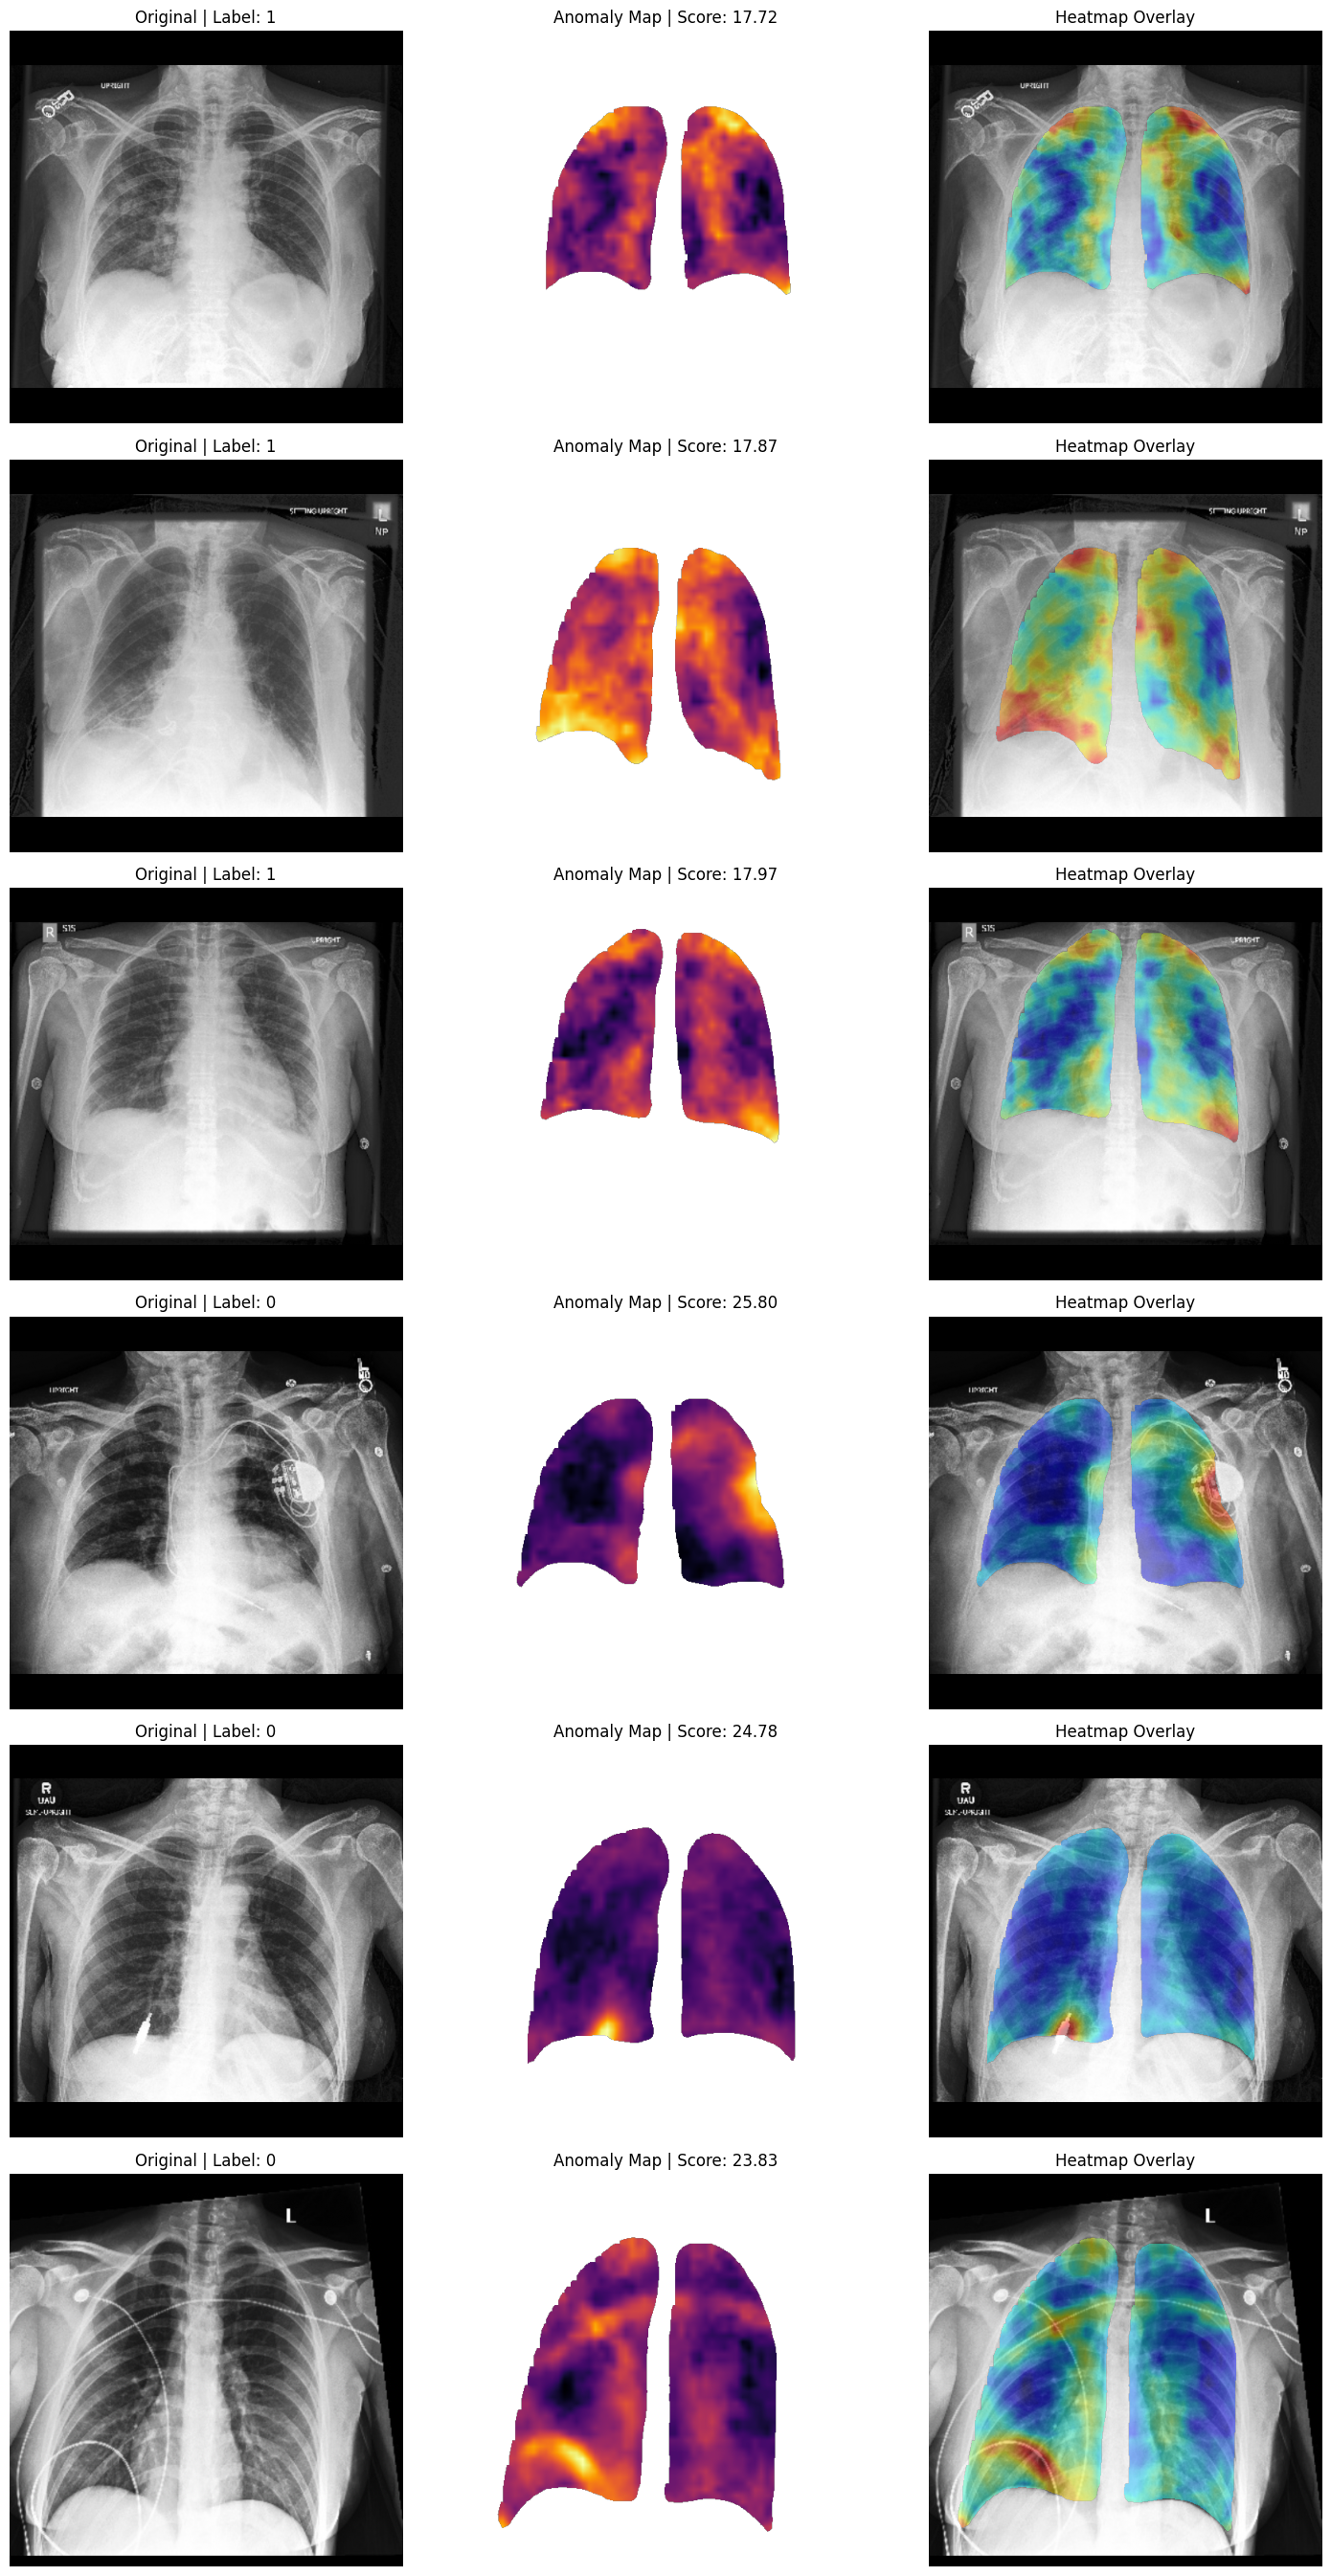

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

examples = pd.concat([
    false_normal.head(3),
    false_abnormal.head(3)
])

fig, axes = plt.subplots(6, 3, figsize=(15, 27))

for i, (_, row) in enumerate(examples.iterrows()):

    image_path = VAL_DIR / row["local_filename"]

    result = calculate_anomaly(image_path)

    image = result["image"]
    heatmap = result["heatmap"]
    mask = result["visible_area"]

    # Скрываем области вне лёгких
    masked_heatmap = np.ma.masked_where(~mask, heatmap)

    # Оригинальный снимок
    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(
        f"Original | Label: {row['label']}"
    )

    # Карта аномальности
    axes[i, 1].imshow(
        masked_heatmap,
        cmap="inferno"
    )
    axes[i, 1].set_title(
        f"Anomaly Map | Score: {result['score']:.2f}"
    )

    # Карта поверх рентгена
    axes[i, 2].imshow(image, cmap="gray")
    axes[i, 2].imshow(
        masked_heatmap,
        cmap="jet",
        alpha=0.45
    )
    axes[i, 2].set_title("Heatmap Overlay")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip -q install gdown

from pathlib import Path
import gdown

CHESS_DIR = Path("/content/chess")
CHESS_DIR.mkdir(parents=True, exist_ok=True)

CHESS_WEIGHTS = CHESS_DIR / "chess_pretrained.pth.tar"

if not CHESS_WEIGHTS.exists():
    gdown.download(
        id="1IfiuQdKV7en9DFaB0NqNdsDkVbdyoVyD",
        output=str(CHESS_WEIGHTS),
        quiet=False
    )

print("CheSS weights:", CHESS_WEIGHTS)
print("Размер (MB):", round(CHESS_WEIGHTS.stat().st_size / 1024**2, 2))

Downloading...
From (original): https://drive.google.com/uc?id=1IfiuQdKV7en9DFaB0NqNdsDkVbdyoVyD
From (redirected): https://drive.google.com/uc?id=1IfiuQdKV7en9DFaB0NqNdsDkVbdyoVyD&confirm=t&uuid=a96b1b2f-2811-4bc9-a7f1-e34dca73cb3e
To: /content/chess/chess_pretrained.pth.tar
100%|██████████| 370M/370M [00:10<00:00, 35.9MB/s]

CheSS weights: /content/chess/chess_pretrained.pth.tar
Размер (MB): 352.54


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet50

# Создаём ResNet50
chess_encoder = resnet50(weights=None)

# Меняем первый слой с 3 каналов на 1
chess_encoder.conv1 = nn.Conv2d(
    in_channels=1,
    out_channels=64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

# Загружаем веса CheSS
checkpoint = torch.load(
    CHESS_WEIGHTS,
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]

encoder_weights = {}

for key, value in state_dict.items():
    if key.startswith("module.encoder_q.") and not key.startswith("module.encoder_q.fc."):
        new_key = key.replace("module.encoder_q.", "", 1)
        encoder_weights[new_key] = value

missing, unexpected = chess_encoder.load_state_dict(
    encoder_weights,
    strict=False
)

assert set(missing) == {"fc.weight", "fc.bias"}, missing
assert len(unexpected) == 0, unexpected

chess_encoder.fc = nn.Identity()

chess_encoder = chess_encoder.to(DEVICE)
chess_encoder.eval()

for param in chess_encoder.parameters():
    param.requires_grad = False


In [ ]:
import inspect

print(inspect.getsource(extract_patch_features))

@torch.inference_mode()
def extract_patch_features(image_path):
    image_array, regions = get_lung_regions(image_path)

    # Снимок: [1, 3, 512, 512]
    image_tensor = torch.from_numpy(
        image_array.astype("float32") / 255.0
    )

    image_tensor = (
        image_tensor.unsqueeze(0)
        .unsqueeze(0)
        .repeat(1, 3, 1, 1)
        .to(DEVICE)
    )

    image_tensor = (image_tensor - mean) / std

    outputs = encoder(image_tensor)

    # Собираем информацию из соседних позиций
    features_2 = F.avg_pool2d(
        outputs["features_2"],
        kernel_size=3,
        stride=1,
        padding=1,
    )

    features_3 = F.avg_pool2d(
        outputs["features_3"],
        kernel_size=3,
        stride=1,
        padding=1,
    )

    # Приводим карты к одинаковому размеру
    features_3 = F.interpolate(
        features_3,
        size=features_2.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

    feature_map = torch.cat(
        [feature

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class CheSSFeatureExtractor(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        x = self.backbone.conv1(x)
        x = self.backbone.bn1(x)
        x = self.backbone.relu(x)
        x = self.backbone.maxpool(x)

        x = self.backbone.layer1(x)

        features_2 = self.backbone.layer2(x)
        features_3 = self.backbone.layer3(features_2)

        return {
            "features_2": features_2,
            "features_3": features_3,
        }


chess_features = CheSSFeatureExtractor(
    chess_encoder
).to(DEVICE)

chess_features.eval()

print("CheSS Feature Extractor готов!")

CheSS Feature Extractor готов!


In [ ]:
@torch.inference_mode()
def extract_patch_features(image_path):
    image_array, regions = get_lung_regions(image_path)

    # Снимок: [1, 1, 512, 512]
    image_tensor = torch.from_numpy(
        image_array.astype("float32") / 255.0
    )

    image_tensor = (
        image_tensor.unsqueeze(0)
        .unsqueeze(0)
        .to(DEVICE)
    )

    # CheSS использует один канал.
    # Не применяем нормализацию ImageNet.
    outputs = chess_features(image_tensor)

    # Собираем информацию из соседних позиций
    features_2 = F.avg_pool2d(
        outputs["features_2"],
        kernel_size=3,
        stride=1,
        padding=1,
    )

    features_3 = F.avg_pool2d(
        outputs["features_3"],
        kernel_size=3,
        stride=1,
        padding=1,
    )

    # Приводим карты к одинаковому размеру
    features_3 = F.interpolate(
        features_3,
        size=features_2.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

    feature_map = torch.cat(
        [features_2, features_3], dim=1
    )

    height, width = feature_map.shape[-2:]

    # Шаг layer2 — 8 пикселей
    region_tensor = torch.from_numpy(
        regions.astype("int64")
    )

    patch_regions = region_tensor[::8, ::8]

    if patch_regions.shape != (height, width):
        raise ValueError(
            "Размеры карты признаков и регионов не совпадают."
        )

    # [число позиций, 1536]
    vectors = (
        feature_map[0]
        .permute(1, 2, 0)
        .reshape(-1, feature_map.shape[1])
        .cpu()
    )

    region_ids = patch_regions.reshape(-1)

    # Позиции вне лёгких исключаем
    inside_lungs = region_ids > 0

    return vectors[inside_lungs], region_ids[inside_lungs]


In [ ]:
test_path = VAL_DIR / validation.iloc[0]["local_filename"]

vectors, region_ids = extract_patch_features(test_path)

print("Feature size:", vectors.shape)
print("Region size:", region_ids.shape)
print("Unique regions:", torch.unique(region_ids))
print("Has NaN:", torch.isnan(vectors).any().item())


Feature size: torch.Size([973, 1536])
Region size: torch.Size([973])
Unique regions: tensor([1, 2, 3, 4, 5, 6])
Has NaN: False


In [ ]:
print("Config of Memory Bank:")
print("config:", config)
print("K:", K)
print("TOP_FRACTION:", TOP_FRACTION)

print("\n Available variables:")
for name in [
    "train",
    "training",
    "train_df",
    "normal_train",
    "normal_files",
    "train_files",
    "BANK_DIR",
    "BANK_PATH",
    "banks",
    "banks_device",
]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

        if isinstance(obj, pd.DataFrame):
            print("Размер:", obj.shape)
            print("Столбцы:", list(obj.columns))
        elif isinstance(obj, (list, tuple)):
            print("Количество:", len(obj))

Config of Memory Bank:
config: {'encoder': 'resnet50_imagenet_v2', 'regions': 'lung_masks_v1', 'image_size': 512, 'max_vectors': 2000, 'filenames': ['train__patient04881__study3__view1_frontal.jpg', 'train__patient57794__study1__view1_frontal.jpg', 'train__patient13888__study1__view1_frontal.jpg', 'train__patient10368__study8__view2_frontal.jpg', 'train__patient07424__study2__view1_frontal.jpg', 'train__patient00700__study1__view1_frontal.jpg', 'train__patient21741__study1__view1_frontal.jpg', 'train__patient61353__study1__view1_frontal.jpg', 'train__patient30646__study2__view1_frontal.jpg', 'train__patient00120__study1__view1_frontal.jpg', 'train__patient01948__study1__view1_frontal.jpg', 'train__patient06639__study1__view1_frontal.jpg', 'train__patient01818__study1__view1_frontal.jpg', 'train__patient39412__study1__view1_frontal.jpg', 'train__patient14426__study2__view1_frontal.jpg', 'train__patient23196__study3__view1_frontal.jpg', 'train__patient22889__study1__view1_frontal.jpg', '

In [ ]:
from pathlib import Path

chess_config = {
    **config,
    "encoder": "chess_resnet50_v1",
}

CHESS_BANK_DIR = BANK_DIR / "chess_resnet50_v1"
CHESS_BANK_DIR.mkdir(parents=True, exist_ok=True)

print("Encoder:", chess_config["encoder"])
print("Training images:", len(chess_config["filenames"]))
print("Max vectors:", chess_config["max_vectors"])
print("Bank directory:", CHESS_BANK_DIR)

Encoder: chess_resnet50_v1
Training images: 100
Max vectors: 2000
Bank directory: /content/cxr_anomaly_project/memory_banks/imagenet/chess_resnet50_v1


In [ ]:
print("BANK_DIR:", BANK_DIR)
print("VAL_DIR:", VAL_DIR)

print("\nПеременные с путями:")
for name, value in globals().copy().items():
    if isinstance(value, Path):
        print(name, "=", value)

print("\nПример файла:")
print(chess_config["filenames"][0])

BANK_DIR: /content/cxr_anomaly_project/memory_banks/imagenet
VAL_DIR: /content/cxr_anomaly_project/data/validation_ap_100

Переменные с путями:
PROJECT_DIR = /content/cxr_anomaly_project
DATA_DIR = /content/cxr_anomaly_project/data/chexpert_normal_ap_100
IMAGE_DIR = /content/cxr_anomaly_project/data/chexpert_normal_ap_100/images
csv_path = /content/cxr_anomaly_project/data/chexpert_normal_ap_100/train.csv
destination = /content/cxr_anomaly_project/data/demo_ap/train__patient21033__study1__view1_frontal.jpg
backup_dir = /content/cxr_backup
source = /content/cxr_anomaly_project/results
target = /content/cxr_backup/results
temporary = /content/cxr_anomaly_project/data/chexpert_normal_ap_100/images/train__patient00353__study1__view1_frontal.part
image_path = /content/cxr_anomaly_project/data/validation_ap_100/train__patient07316__study1__view1_frontal.jpg
first_path = /content/cxr_anomaly_project/data/chexpert_normal_ap_100/images/train__patient04881__study3__view1_frontal.jpg
BANK_DIR = /

In [ ]:
from pathlib import Path
import torch
import numpy as np
from tqdm.auto import tqdm

CHESS_BANK_DIR = PROJECT_DIR / "memory_banks" / "chess"
CHESS_BANK_DIR.mkdir(parents=True, exist_ok=True)

CHESS_CHECKPOINT = CHESS_BANK_DIR / "regional_ap_masks_v1.pt"

train_filenames = config["filenames"]

missing_files = [
    name for name in train_filenames
    if not (IMAGE_DIR / name).exists()
]

print("Обучающих снимков:", len(train_filenames))
print("Отсутствует:", len(missing_files))
print("CheSS Bank:", CHESS_CHECKPOINT)

if missing_files:
    raise FileNotFoundError(
        f"Отсутствуют снимки: {missing_files[:5]}"
    )

Обучающих снимков: 100
Отсутствует: 0
CheSS Bank: /content/cxr_anomaly_project/memory_banks/chess/regional_ap_masks_v1.pt


In [ ]:
import random

torch.manual_seed(42)

chess_all_vectors = {region: [] for region in range(1, 7)}
chess_failed = []

for filename in tqdm(train_filenames, desc="CheSS: извлечение признаков"):
    path = IMAGE_DIR / filename

    try:
        vectors, region_ids = extract_patch_features(path)

        for region in range(1, 7):
            region_vectors = vectors[region_ids == region]

            if len(region_vectors) > 0:
                chess_all_vectors[region].append(region_vectors)

    except (ValueError, RuntimeError) as e:
        chess_failed.append({
            "filename": filename,
            "error": str(e)
        })
        print(f"skipped {filename}: {e}")

print("\nSkipped x-rays:", len(chess_failed))

CheSS: извлечение признаков:   0%|          | 0/100 [00:00<?, ?it/s]


Skipped x-rays: 0


In [ ]:
chess_banks = {}

MAX_VECTORS = chess_config["max_vectors"]

for region in range(1, 7):
    if not chess_all_vectors[region]:
        raise ValueError(
            f"no indications for the region {region}"
        )

    all_vectors = torch.cat(
        chess_all_vectors[region],
        dim=0
    )

    if len(all_vectors) > MAX_VECTORS:
        indices = torch.randperm(len(all_vectors))[:MAX_VECTORS]
        all_vectors = all_vectors[indices]

    chess_banks[region] = all_vectors.contiguous()

    print(
        f"Region {region}: "
        f"{chess_banks[region].shape}"
    )

torch.save(
    {
        "config": chess_config,
        "banks": chess_banks,
        "failed": chess_failed,
    },
    CHESS_CHECKPOINT
)

print("\nCheSS Memory Bank saved. ")
print(CHESS_CHECKPOINT)

Region 1: torch.Size([2000, 1536])
Region 2: torch.Size([2000, 1536])
Region 3: torch.Size([2000, 1536])
Region 4: torch.Size([2000, 1536])
Region 5: torch.Size([2000, 1536])
Region 6: torch.Size([2000, 1536])

CheSS Memory Bank saved. 
/content/cxr_anomaly_project/memory_banks/chess/regional_ap_masks_v1.pt


In [ ]:
chess_checkpoint = torch.load(
    CHESS_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

chess_banks = chess_checkpoint["banks"]

chess_banks_device = {
    region: bank.to(DEVICE)
    for region, bank in chess_banks.items()
}

# Наша calculate_anomaly использует banks_device.
# Сохраняем ImageNet-банк отдельно.
imagenet_banks_device = banks_device

banks_device = chess_banks_device

print("CheSS Memory Bank подключён!")

for region, bank in banks_device.items():
    print(f"Регион {region}: {tuple(bank.shape)}")

CheSS Memory Bank подключён!
Регион 1: (2000, 1536)
Регион 2: (2000, 1536)
Регион 3: (2000, 1536)
Регион 4: (2000, 1536)
Регион 5: (2000, 1536)
Регион 6: (2000, 1536)


In [ ]:
import io
import json
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

CHESS_SCORES_CSV = VAL_DIR / "scores_chess_v1.csv"
CHESS_SETTINGS_JSON = VAL_DIR / "settings_chess_v1.json"
CHESS_ERRORS_CSV = VAL_DIR / "errors_chess_v1.csv"

# Убеждаемся, что подключён CheSS
assert chess_features.training is False
assert chess_encoder.conv1.in_channels == 1

for region in range(1, 7):
    assert region in banks_device
    assert torch.equal(
        banks_device[region].cpu(),
        chess_banks[region].cpu()
    ), f"Not correct Memory Bank: region {region}"

settings = {
    "bank_config": chess_config,
    "K": K,
    "top_fraction": TOP_FRACTION,
}

if CHESS_SETTINGS_JSON.exists():
    saved_settings = json.loads(
        CHESS_SETTINGS_JSON.read_text()
    )

    if saved_settings != settings:
        raise ValueError("Settings of CheSS has changed.")
else:
    CHESS_SETTINGS_JSON.write_text(
        json.dumps(settings, indent=2)
    )

if CHESS_SCORES_CSV.exists():
    records = pd.read_csv(CHESS_SCORES_CSV).to_dict("records")
else:
    records = []

if CHESS_ERRORS_CSV.exists():
    errors = pd.read_csv(CHESS_ERRORS_CSV).to_dict("records")
else:
    errors = []

finished = {r["local_filename"] for r in records}
failed = {r["local_filename"] for r in errors}

print("Had done:", len(finished))
print("Had skipped:", len(failed))

for row in tqdm(
    validation.itertuples(index=False),
    total=len(validation),
    desc="CheSS Validation",
):
    if row.local_filename in finished or row.local_filename in failed:
        continue

    image_path = VAL_DIR / row.local_filename

    try:
        if not image_path.exists() or not image_is_valid(image_path):
            content = download_file(row.kaggle_path)

            with Image.open(io.BytesIO(content)) as image:
                image.verify()

            temporary_image = image_path.with_suffix(".part")
            temporary_image.write_bytes(content)
            temporary_image.replace(image_path)

        result = calculate_anomaly(image_path)

        score = float(result["score"])
        if not np.isfinite(score):
            raise ValueError("Not right anomaly score")

        records.append({
            "patient_id": row.patient_id,
            "local_filename": row.local_filename,
            "label": int(row.label),
            "score": score,
        })

        temporary_csv = CHESS_SCORES_CSV.with_suffix(".tmp")
        pd.DataFrame(records).to_csv(temporary_csv, index=False)
        temporary_csv.replace(CHESS_SCORES_CSV)

        finished.add(row.local_filename)

    except Exception as e:
        print(f"Error: {row.local_filename}: {e}")

        errors.append({
            "patient_id": row.patient_id,
            "local_filename": row.local_filename,
            "error": str(e),
        })

        temporary_errors = CHESS_ERRORS_CSV.with_suffix(".tmp")
        pd.DataFrame(errors).to_csv(
            temporary_errors, index=False
        )
        temporary_errors.replace(CHESS_ERRORS_CSV)

        failed.add(row.local_filename)

scores_chess = pd.DataFrame(records)

print("\nCheSS Validation done")
print("Success:", len(scores_chess))
print("Erros:", len(errors))
print("All:", len(validation))

display(scores_chess.head())

Had done: 0
Had skipped: 0


CheSS Validation:   0%|          | 0/100 [00:00<?, ?it/s]

Error: train__patient59666__study1__view1_frontal.jpg: Модель не выделила одно из лёгких.

CheSS Validation done
Success: 99
Erros: 1
All: 100


,patient_id,local_filename,label,score
0,patient14846,train__patient14846__study3__view1_frontal.jpg,0,4.554094
1,patient07651,train__patient07651__study7__view1_frontal.jpg,0,3.977994
2,patient31087,train__patient31087__study1__view1_frontal.jpg,0,4.757810
3,patient22371,train__patient22371__study2__view1_frontal.jpg,0,4.992507
4,patient22815,train__patient22815__study4__view1_frontal.jpg,0,4.523638


Общие снимки: 99


,Encoder,AUROC,Average Precision,Images
0,ImageNet,0.528571,0.548980,99
1,CheSS,0.628980,0.669898,99


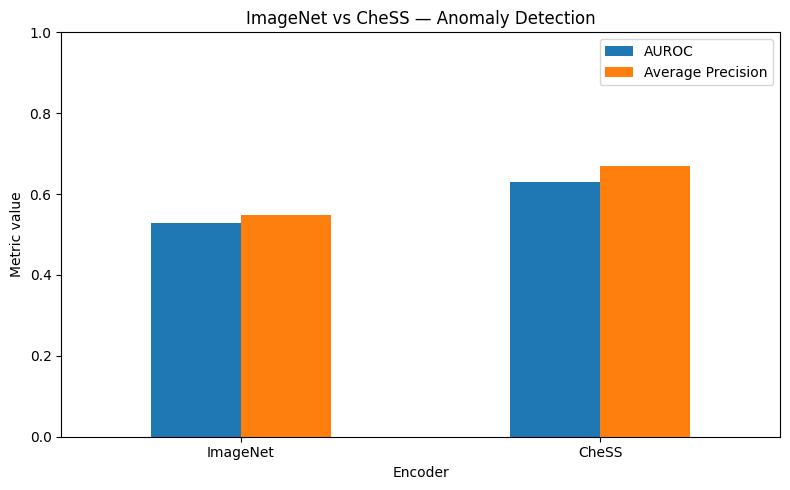

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import matplotlib.pyplot as plt

imagenet_scores = pd.read_csv(
    VAL_DIR / "scores_imagenet_v1.csv"
)

chess_scores = pd.read_csv(
    VAL_DIR / "scores_chess_v1.csv"
)

comparison = imagenet_scores[
    ["local_filename", "label", "score"]
].merge(
    chess_scores[["local_filename", "label", "score"]],
    on=["local_filename", "label"],
    suffixes=("_imagenet", "_chess"),
    validate="one_to_one"
)

print("Общие снимки:", len(comparison))

if comparison["label"].nunique() != 2:
    raise ValueError("Для AUROC нужны оба класса.")

results = []

for model, column in [
    ("ImageNet", "score_imagenet"),
    ("CheSS", "score_chess"),
]:
    auroc = roc_auc_score(
        comparison["label"],
        comparison[column]
    )

    ap = average_precision_score(
        comparison["label"],
        comparison[column]
    )

    results.append({
        "Encoder": model,
        "AUROC": auroc,
        "Average Precision": ap,
        "Images": len(comparison),
    })

results_df = pd.DataFrame(results)

display(results_df)

ax = results_df.set_index("Encoder")[
    ["AUROC", "Average Precision"]
].plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_ylim(0, 1)
ax.set_ylabel("Metric value")
ax.set_title("ImageNet vs CheSS — Anomaly Detection")
plt.tight_layout()
plt.show()

In [ ]:
import torch
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

banks_device = chess_banks_device

K_VALUES = [1, 3, 5]
TOP_VALUES = [0.01, 0.05, 0.10]
MAX_K = max(K_VALUES)

DISTANCES_PATH = VAL_DIR / "chess_knn_distances_10.pt"

# Загружаем уже проверенные CheSS снимки
chess_saved = pd.read_csv(
    VAL_DIR / "scores_chess_v1.csv"
)

# Выбираем 5 Normal и 5 Abnormal случайно,
# но с фиксированным random_state
normal_5 = chess_saved[
    chess_saved["label"] == 0
].sample(n=5, random_state=42)

abnormal_5 = chess_saved[
    chess_saved["label"] == 1
].sample(n=5, random_state=42)

chess_small = pd.concat(
    [normal_5, abnormal_5],
    ignore_index=True
)

print("Выбрано снимков:", len(chess_small))
print(chess_small["label"].value_counts())

distance_records = []
failed_images = []

for row in tqdm(
    chess_small.itertuples(index=False),
    total=len(chess_small),
    desc="CheSS KNN — 10 images"
):
    image_path = VAL_DIR / row.local_filename

    try:
        vectors, region_ids = extract_patch_features(
            image_path
        )

        distances_all = torch.empty(
            (len(vectors), MAX_K),
            dtype=torch.float32
        )

        for region in range(1, 7):
            positions = torch.where(
                region_ids == region
            )[0]

            if len(positions) == 0:
                continue

            reference = chess_banks_device[region]

            if len(reference) < MAX_K:
                raise ValueError(
                    f"Недостаточно векторов в регионе {region}"
                )

            for chunk_positions in positions.split(256):
                query = vectors[
                    chunk_positions
                ].to(DEVICE)

                distances = torch.cdist(
                    query,
                    reference,
                    p=2
                )

                nearest = distances.topk(
                    k=MAX_K,
                    largest=False,
                    dim=1
                ).values

                distances_all[chunk_positions] = (
                    nearest.cpu()
                )

        distance_records.append({
            "local_filename": row.local_filename,
            "label": int(row.label),
            "distances": distances_all,
        })

    except Exception as e:
        print(f"Ошибка: {row.local_filename}: {e}")
        failed_images.append(row.local_filename)

torch.save(
    distance_records,
    DISTANCES_PATH
)

print("\nГотово!")
print("Обработано:", len(distance_records))
print("Ошибки:", len(failed_images))

Выбрано снимков: 10
label
0    5
1    5
Name: count, dtype: int64


CheSS KNN — 10 images:   0%|          | 0/10 [00:00<?, ?it/s]


Готово!
Обработано: 10
Ошибки: 0


In [ ]:
import math
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

results = []

for k in K_VALUES:
    for top_fraction in TOP_VALUES:

        labels = []
        image_scores = []

        for record in distance_records:

            # Среднее расстояние до K соседей
            patch_scores = (
                record["distances"][:, :k]
                .mean(dim=1)
            )

            top_count = max(
                1,
                math.ceil(
                    len(patch_scores) * top_fraction
                )
            )

            # Среднее по наиболее аномальным патчам
            score = patch_scores.topk(
                top_count
            ).values.mean().item()

            labels.append(record["label"])
            image_scores.append(score)

        if len(set(labels)) < 2:
            raise ValueError(
                "Для оценки нужны оба класса."
            )

        results.append({
            "K": k,
            "TOP_FRACTION": top_fraction,
            "AUROC": roc_auc_score(
                labels,
                image_scores
            ),
            "AP": average_precision_score(
                labels,
                image_scores
            ),
            "Images": len(labels),
        })

tuning_results = pd.DataFrame(results)

tuning_results = tuning_results.sort_values(
    "AUROC",
    ascending=False
)

display(tuning_results.round(4))

tuning_results.to_csv(
    VAL_DIR / "chess_parameter_exploration.csv",
    index=False
)

,K,TOP_FRACTION,AUROC,AP,Images
2,1,0.10,0.84,0.8529,10
5,3,0.10,0.76,0.8083,10
8,5,0.10,0.72,0.7893,10
3,3,0.01,0.68,0.7593,10
1,1,0.05,0.68,0.7593,10
0,1,0.01,0.64,0.7393,10
4,3,0.05,0.64,0.7393,10
7,5,0.05,0.64,0.7393,10
6,5,0.01,0.60,0.7254,10


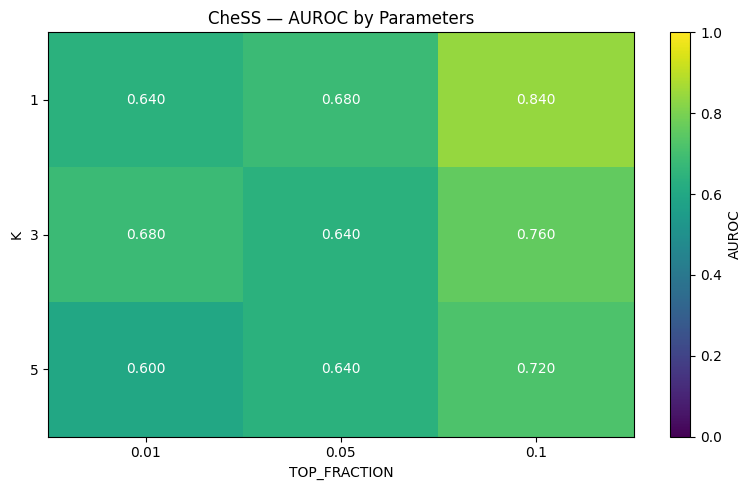

In [ ]:
import matplotlib.pyplot as plt

pivot = tuning_results.pivot(
    index="K",
    columns="TOP_FRACTION",
    values="AUROC"
)

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(
    pivot.values,
    cmap="viridis",
    vmin=0,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)

ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

ax.set_xlabel("TOP_FRACTION")
ax.set_ylabel("K")
ax.set_title("CheSS — AUROC by Parameters")

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(
            j, i,
            f"{pivot.values[i, j]:.3f}",
            ha="center",
            va="center",
            color="white"
        )

plt.colorbar(im, label="AUROC")
plt.tight_layout()
plt.show()

In [ ]:
candidate_names=list(config["filenames"])
example=None
for name in candidate_names[:25]:
    example=safe_region(name)
    if example is not None: break
if example is None: raise RuntimeError("No segmentable training image found for Figure 1")
im,regions=example
fig,axs=plt.subplots(1,3,figsize=(12,4.2))
axs[0].imshow(im,cmap="gray"); axs[0].set_title("(a) Original radiograph")
axs[1].imshow(im,cmap="gray"); axs[1].imshow(np.ma.masked_where(regions==0,regions>0),cmap="Greens",alpha=.42,vmin=0,vmax=1); axs[1].set_title("(b) Predicted lung mask")
axs[2].imshow(im,cmap="gray"); axs[2].imshow(np.ma.masked_where(regions==0,regions),cmap=REGION_PALETTE,alpha=.57,vmin=-.5,vmax=6.5); axs[2].set_title("(c) Six anatomical regions")
for ax in axs: ax.axis("off")
fig.legend(handles=[Patch(facecolor=REGION_PALETTE(i/6),label=f"R{i}") for i in range(1,7)],loc="lower center",ncol=6,bbox_to_anchor=(.5,-.02),frameon=False)
fig.tight_layout(rect=[0,.04,1,1]); save_fig(1,fig); plt.show()

NameError: name 'safe_region' is not defined